<a href="https://colab.research.google.com/github/guyberelzon-rgb/Galaxy-Rotation-CNN/blob/main/code_deep_learning_project_ariel_sobol_guy_berelzon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rotation Robustness in Galaxy Morphology Classification

**Deep Learning Final Project | TAU 2026**
*Ariel Sobol & Guy Berelzon*

## Overview
We classify galaxy images into 10 morphological types (spiral, elliptical, edge-on, etc.)
using a transfer-learning CNN, and study how robust the model is to image rotations
and flips - motivated by the fact that a galaxy has no "correct" orientation and can appear in different angle deends on when its viewed from.

## Research question
To what extent is a transfer-learning-based CNN invariant to rotations and flips when
classifying galaxy morphology, and to what degree do data augmentation versus architectural
choices (backbone type and transfer-learning strategy) improve its robustness?

**Sub-questions**
1. How much does the baseline's accuracy drop when test images are rotated by various angles and flipped?
2. Does training with rotation/flip augmentation restore accuracy across the range of angles?
3. Do architectural choices: backbone type/depth (VGG vs. ResNet vs. EfficientNet) and the
   transfer learning strategy - affect robustness to rotation?

## Dataset
**Galaxy10 DECaLS** — 17,736 color images (256×256), 10 classes, labels from Galaxy Zoo votes. Link: https://astronn.readthedocs.io/en/latest/galaxy10sdss.html

## 1. Setup — mount Drive and import libraries

In [ ]:
# Mount Google Drive so we can read the dataset file
from google.colab import drive
drive.mount('/content/drive')

# Core libraries
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from scipy import ndimage
from scipy.ndimage import rotate as scipy_rotate
from skimage.metrics import structural_similarity as ssim
import time
import pandas as pd

# Nicer plot defaults
plt.rcParams['figure.dpi'] = 110

# Path to the dataset (inside MyDrive/Galaxy_Databases)
FILE_PATH = '/content/drive/MyDrive/Galaxy_Databases/Galaxy10_DECals.h5'
print('File found:', os.path.exists(FILE_PATH))

Mounted at /content/drive
File found: True


# Step 1 - Data

## 1. Load the dataset
The file is HDF5 (`.h5`) - a data container read with the `h5py` library.
It holds the galaxy `images` and their class labels (`ans`).

In [ ]:
# Read images and labels from the HDF5 file
with h5py.File(FILE_PATH, 'r') as f:
    print('Datasets inside file:', list(f.keys()))
    images = np.array(f['images'])   # (17736, 256, 256, 3), uint8, values 0-255
    labels = np.array(f['ans'])      # (17736,), values 0-9

# Human-readable names for the 10 classes
class_names = [
    'Disturbed', 'Merging', 'Round Smooth', 'In-between Smooth',
    'Cigar-shaped Smooth', 'Barred Spiral', 'Unbarred Tight Spiral',
    'Unbarred Loose Spiral', 'Edge-on w/o Bulge', 'Edge-on w/ Bulge'
]

print('Images shape:', images.shape, '| dtype:', images.dtype)
print('Labels shape:', labels.shape, '| dtype:', labels.dtype)
print('Pixel value range:', images.min(), '-', images.max())

Datasets inside file: ['ans', 'dec', 'images', 'pxscale', 'ra', 'redshift']
Images shape: (17736, 256, 256, 3) | dtype: uint8
Labels shape: (17736,) | dtype: uint8
Pixel value range: 0 - 255


In [ ]:
with h5py.File(FILE_PATH, 'r') as f:
    keys = list(f.keys())
    print('Number of datasets:', len(keys))
    for k in keys:
        print(f'  {k}: shape={f[k].shape}, dtype={f[k].dtype}')

Number of datasets: 6
  ans: shape=(17736,), dtype=uint8
  dec: shape=(17736,), dtype=float64
  images: shape=(17736, 256, 256, 3), dtype=uint8
  pxscale: shape=(17736,), dtype=float64
  ra: shape=(17736,), dtype=float64
  redshift: shape=(17736,), dtype=float64


**The six datasets**

* ans - this dataset contains the label for each image, an integer 0-9 corresponding to the 10 galaxy classes. This is the answer key that the model learns to predict

* dec, ra - Both sky coordinates astronomers use (like longitude (ra) and latitude (dec)). The combination pinpoints where each galaxy was observed

* images - The shape is (17736, 256,256,3), dtype uint8. This is the 17,736 galaxy pictures, each with 256 X 256 pixels with 3 color channels (R,G,B), with values ranging between 0 - 255. This dataset is the raw photo data.

* pxscale - pixal scale, in arcseconds per pixel. It is usefull  when converting 256 pixel wide data into an actual angular size in the sky

* redshift - a number describing how much the galaxy's light has stretched toward red wavelengths due to the univers's expansion. A higher redshift value means the galaxy we are looking at is farther away and we're seeing it further back in time.

## Examples of the loaded data ##


In [ ]:
with h5py.File(FILE_PATH, 'r') as f:
    img = f['images'][0]     # (256, 256, 3) uint8
    label = f['ans'][0]

# Full array is 256x256x3 = 196,608 numbers — look at a small corner instead
print(img[:5, :5, 0])   # top-left 5x5 patch, red channel only, values 0-255

[[68 58 40 25 25]
 [61 52 29 13 18]
 [30 24 15 23 39]
 [29 14  9 34 60]
 [37 28 28 46 64]]


In the following example, the picture on the right is the top left 10 X 10 of the image on the left. Since the range of the pixels is 0-256, the higher the number the brighter the pixel is. The darker the area, the lower the pixels are.

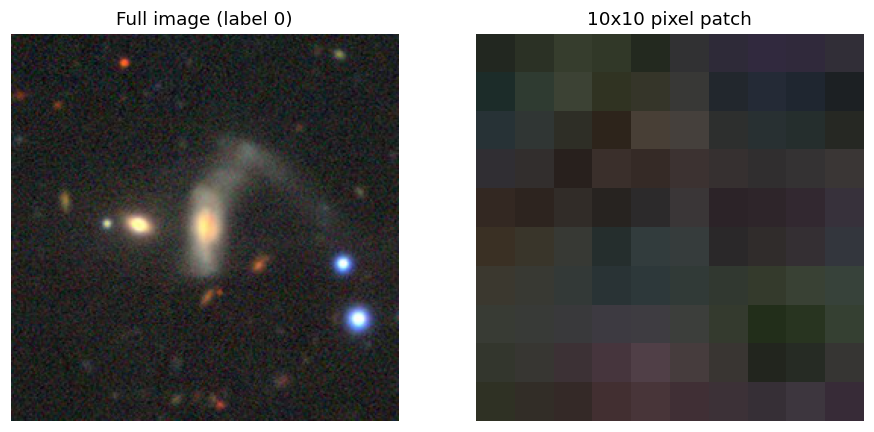

10x10 patch, R channel:
 [[34 43 54 49 35 49 46 49 48 49]
 [28 47 60 48 53 56 34 36 31 28]
 [39 48 46 45 72 69 45 40 37 38]
 [48 50 40 58 53 60 54 48 52 58]
 [51 45 49 39 44 58 44 46 50 55]
 [58 57 55 37 50 54 42 48 52 51]
 [59 56 51 41 45 49 49 52 57 55]
 [56 56 57 61 62 60 52 34 40 53]
 [51 55 60 70 80 70 57 34 38 54]
 [47 50 52 66 72 64 60 54 61 55]]


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img)
axes[0].set_title(f'Full image (label {label})')
axes[1].imshow(img[100:110, 100:110])  # zoom into a 10x10 patch
axes[1].set_title('10x10 pixel patch')
for a in axes: a.axis('off')
plt.show()

print('10x10 patch, R channel:\n', img[100:110, 100:110, 0])

When looking at a larger example, Here we compare a Dark Patch with a bright patch. As you can see, the numbers in the bright patch in the mid right patch are higher.  The range of the bright patch has a higher mean than the dark patch, pointing out the difference in the pixels.  



Brightest pixel value: 254.66666666666666
Located at row,col: 151 218


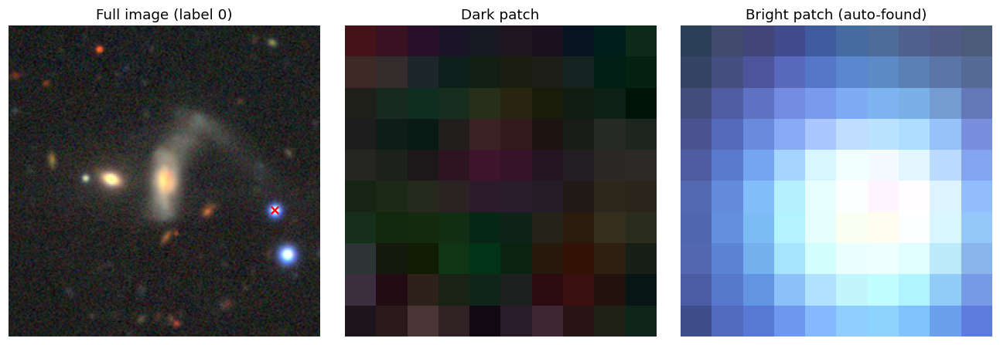


Dark patch, R channel (background, low values):
[[68 58 40 25 25 29 25  7  0 13]
 [61 52 29 13 18 28 29 20  0  5]
 [30 24 15 23 39 39 25 17 12  0]
 [29 14  9 34 60 51 29 26 38 28]
 [37 28 28 46 64 54 37 35 44 45]
 [22 28 38 43 44 41 36 32 43 41]
 [22 19 21 17  6 15 37 41 53 42]
 [44 21 16 16  2 10 39 50 47 24]
 [60 33 46 24 15 30 44 58 35  7]
 [30 42 73 48 18 41 62 40 31 14]]

Bright patch, R channel (near max, high values):
[[ 43  66  67  65  63  70  77  79  82  76]
 [ 53  70  77  88  86  90  92  91  91  85]
 [ 69  80  95 115 122 127 126 121 115 100]
 [ 75  83 106 136 170 191 187 174 151 121]
 [ 78  89 117 164 216 242 243 226 186 132]
 [ 83  98 130 180 230 254 255 255 220 145]
 [ 78 101 125 177 228 251 255 252 217 149]
 [ 84  90 116 166 212 235 237 224 187 138]
 [ 75  86  99 140 176 194 193 176 145 118]
 [ 62  81  87 110 133 143 140 127 107  94]]

Side-by-side range check:
  Dark patch  -> min 0, max 73, mean 30.1
  Bright patch -> min 43, max 255, mean 172.6


In [ ]:
with h5py.File(FILE_PATH, 'r') as f:
    img = f['images'][0]
    label = f['ans'][0]

# Brightness = average across R,G,B for each pixel
brightness = img.mean(axis=2)   # shape (256, 256)

# Find the single brightest pixel's location
max_row, max_col = np.unravel_index(np.argmax(brightness), brightness.shape)
print('Brightest pixel value:', brightness[max_row, max_col])
print('Located at row,col:', max_row, max_col)

# Grab a 10x10 patch centered on that bright pixel
r0, c0 = max(0, max_row - 5), max(0, max_col - 5)
bright_patch = img[r0:r0+10, c0:c0+10]

# Dark corner patch for comparison
dark_patch = img[0:10, 0:10]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img)
axes[0].scatter([c0+5], [r0+5], c='red', s=40, marker='x')
axes[0].set_title(f'Full image (label {label})')
axes[1].imshow(dark_patch); axes[1].set_title('Dark patch')
axes[2].imshow(bright_patch); axes[2].set_title('Bright patch (auto-found)')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

print('\nDark patch, R channel (background, low values):')
print(dark_patch[:,:,0])

print('\nBright patch, R channel (near max, high values):')
print(bright_patch[:,:,0])

print('\nSide-by-side range check:')
print(f'  Dark patch  -> min {dark_patch.min()}, max {dark_patch.max()}, mean {dark_patch.mean():.1f}')
print(f'  Bright patch -> min {bright_patch.min()}, max {bright_patch.max()}, mean {bright_patch.mean():.1f}')

From this example, and the 10 known classifiers of galaxies we have in the file, i would expect the following of the grid of numbers and pattern per label of a galaxy:
* Distributed - numbers jump around without a regular pattern, with groups of bright patches and messy edges that do not have a clean shpae

* Merging - two separate clusters of bright/hig numbers close together with a cluster of medium value numbers connecting them

* Round Smooth - numbers fade gently and evenly outward from the bright center in all different directions.

* In-between Smooth - similar pattern as the Round Smooth, but stretched more in one direction and not a perfect circle like the Round Smooth4

* Cigar-Shaped Smooth - a long, thin group of high numbers with a smooth fade on either side, much longer than it is wide.

* Barred Spiral - a straight line of high numbers (bright) cutting through a bright center, with curving spiral arms of spiking/dipping numbers branching out of it.

* Unbarred Tight Spiral - twisting branches of spikinig numbers wound closely around the center.

* Unbarred Loose Spiral - same twisting branch and dip patterns as a tight spiral, but the numeric branches are spaced farther apart.

* Edge on w/o Bulge - a thini, flat line of high numbers with sharp edges , no extra bumps of brightness in the middle.

* Edge on w/Bulge - same thin flat line, but with an added cluster of extra-high numbers bulging out of the center.

## Dataset First-Look Summary ##

The Galaxy10_DECaLS.h5 file has 6 different datasets. Two of the datasets are the central datapoints of our analysis: images and ans which is the answer key. Together they are used to teach the models how to predict the galaxies. The other four - ra, dec, redshift and pxscale are metadata used to understand roughly the position of each galaxy is. A galaxy's position in the sky does not affect whether the model handles rotation well. Redshift tells the distance/age which correlates with apparent size and image noise, but not orientation. This would be relevant if we were asking if the model performs worse or better on more distant, fainter galaxies. That is a different question than what we are asking. pxscale does not touch orientation invariance either.

We decided to use only the images and ans for the project, since our research question isn't about where galaxies are in the sky, it's about whether a computer can still recognize a galaxy's shpae correctly even if you spin the photo around. That question only needs the picture and the correct shape label since our questoin is purely about pixel-level orientation robustness.


## 2. Exploratory Data Analysis (EDA)
Before modeling, we check: how many images per class, whether classes are balanced,
and what the galaxies actually look like.

### Class Distribution of Images

In the class distribution chart, we look at how many images are there in each class

Total images: 17736
Number of classes: 10

  0  Disturbed                 1081  ( 6.1%)
  1  Merging                   1853  (10.4%)
  2  Round Smooth              2645  (14.9%)
  3  In-between Smooth         2027  (11.4%)
  4  Cigar-shaped Smooth        334  ( 1.9%)
  5  Barred Spiral             2043  (11.5%)
  6  Unbarred Tight Spiral     1829  (10.3%)
  7  Unbarred Loose Spiral     2628  (14.8%)
  8  Edge-on w/o Bulge         1423  ( 8.0%)
  9  Edge-on w/ Bulge          1873  (10.6%)


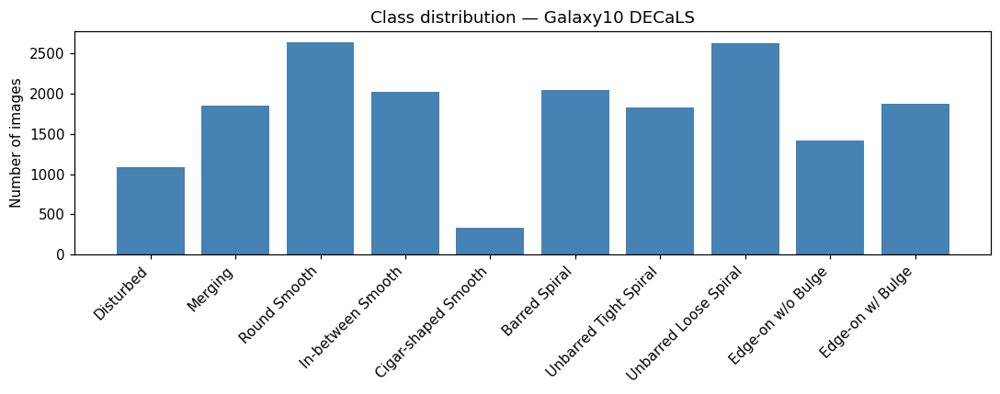

In [ ]:

counts = Counter(labels.tolist())

print('Total images:', len(labels))
print('Number of classes:', len(counts))
print()
for c in range(len(class_names)):
    print(f'  {c}  {class_names[c]:<24} {counts[c]:>5}  ({counts[c]/len(labels)*100:4.1f}%)')


plt.figure(figsize=(10, 4))
plt.bar([class_names[c] for c in range(len(class_names))],
        [counts[c] for c in range(len(class_names))],
        color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of images')
plt.title('Class distribution — Galaxy10 DECaLS')
plt.tight_layout()
plt.show()

The distribution points out the following:
Classes range from 334 images to 2,645. Roughly an 8x gap between the smallest and largest classification. This matters for the future analysis since the model can reach a high accuracy just by being good at the most common classifications and being bad with the rare ones. We'll trach this by reporting per-class precision/recall throughouth, not just overall accuracy. Further down the analysis, we will see that the Cigar-shaped Smooth galaxy, the smallest one, does turn out to be one of the harder classifications for the baseline model.

### The Datasets Galaxy Classification Examples

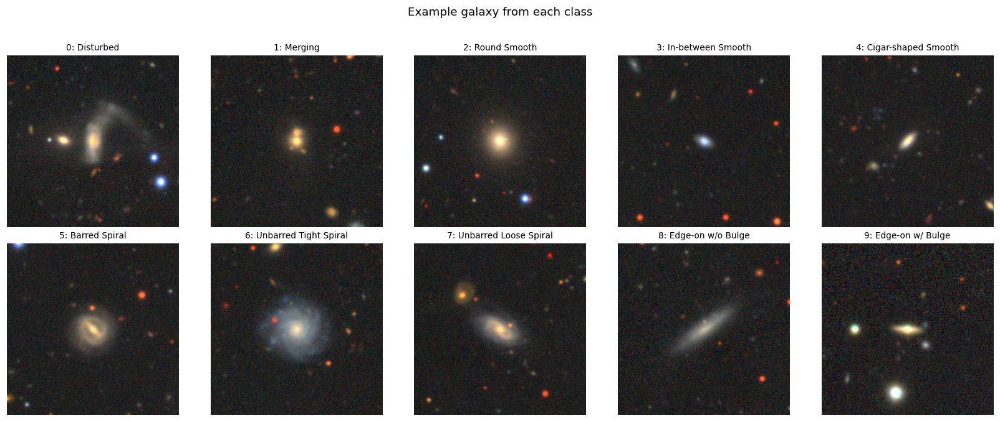

In [ ]:
# Show one example galaxy from each of the 10 classes
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for c, ax in enumerate(axes.flat):
    idx = np.where(labels == c)[0][0]
    ax.imshow(images[idx])
    ax.set_title(f'{c}: {class_names[c]}', fontsize=9)
    ax.axis('off')
plt.suptitle('Example galaxy from each class', y=1.02)
plt.tight_layout()
plt.show()

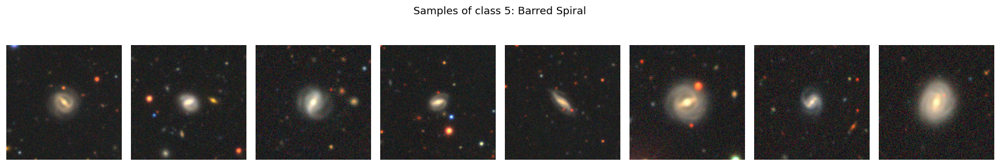

In [ ]:
# Example: Class 5 = Barred Spiral Look at several examples of a single class to see intra-class variety
CLASS_TO_INSPECT = 5

idxs = np.where(labels == CLASS_TO_INSPECT)[0][:8]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for ax, idx in zip(axes, idxs):
    ax.imshow(images[idx])
    ax.axis('off')
plt.suptitle(f'Samples of class {CLASS_TO_INSPECT}: {class_names[CLASS_TO_INSPECT]}', y=1.05)
plt.tight_layout()
plt.show()

### Data Quality - Checking for corrupted data and data problems

We check for corrupted or blank images by measuring how much visual variety is in each image, using per-image pixel standard deviation as a proxy: a photo that's mostly a flat, uniform color would have very low variety and a low std score. We flag the bottom 1% of images by this score as "suspicious." Since there will always be a bottom 1% in any dataset, that alone doesn't prove anything — we need to check what the histogram actually looks like near that cutoff. If there were a genuine group of broken images (corrupted downloads, blank frames, sensor glitches), we'd expect them to show up as a small cluster sitting separately from the rest of the distribution, cut off near zero. If instead the low end just tapers smoothly into the main distribution with no gap, that means the "lowest variety" images aren't broken — they're simply the natural low end of one continuous spectrum.

178 images flagged as low-variance (possible blank/corrupted)


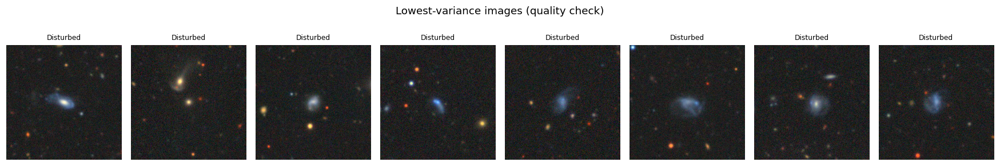

In [ ]:
# Per-image std, computed in batches to avoid a 28GB float64 blowup
batch_size = 500
n = len(images)
per_image_std = np.empty(n, dtype=np.float32)

for start in range(0, n, batch_size):
    end = min(start + batch_size, n)
    batch = images[start:end].astype(np.float32)
    per_image_std[start:end] = batch.reshape(end - start, -1).std(axis=1)
    del batch

blank_thresh = np.percentile(per_image_std, 1)
suspicious = np.where(per_image_std < blank_thresh)[0]
print(f'{len(suspicious)} images flagged as low-variance (possible blank/corrupted)')

fig, axes = plt.subplots(1, min(8, len(suspicious)), figsize=(16, 2.5))
for ax, idx in zip(np.atleast_1d(axes), suspicious[:8]):
    ax.imshow(images[idx]); ax.set_title(class_names[labels[idx]], fontsize=8); ax.axis('off')
plt.suptitle('Lowest-variance images (quality check)', y=1.05)
plt.tight_layout(); plt.show()

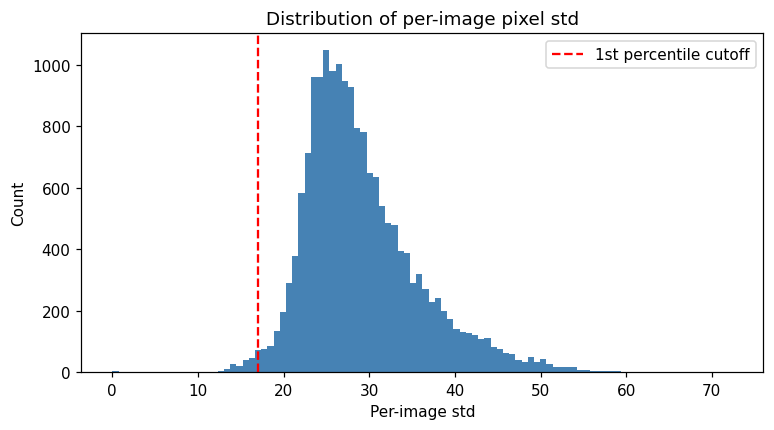

  Disturbed                15
  Merging                  10
  Round Smooth             78
  In-between Smooth        20
  Cigar-shaped Smooth      15
  Barred Spiral            6
  Unbarred Tight Spiral    4
  Unbarred Loose Spiral    10
  Edge-on w/o Bulge        7
  Edge-on w/ Bulge         13


In [ ]:
# Is there a natural gap (true outliers) or a smooth tail
plt.figure(figsize=(8, 4))
plt.hist(per_image_std, bins=100, color='steelblue')
plt.axvline(blank_thresh, color='red', linestyle='--', label='1st percentile cutoff')
plt.xlabel('Per-image std'); plt.ylabel('Count'); plt.legend()
plt.title('Distribution of per-image pixel std')
plt.show()

# Do flagged images cluster in specific classes
flagged_classes = labels[suspicious]
for c in range(len(class_names)):
    n = (flagged_classes == c).sum()
    if n > 0:
        print(f'  {class_names[c]:<24} {n}')

The histogram has two parts worth reading differently. The long right tail is images with unusually high std — strong contrast between a bright galaxy and dark background, or a bright foreground star in frame. That's not what we're checking for here; it's just normal variety, not a red flag. What matters is the left edge, near the red dashed line marking our bottom-1% cutoff (std ≈ 17). This is where corrupted images would show up if they existed — as a small bump isolated from the rest. Instead, the distribution tapers smoothly down into the main hill with no gap and no separate cluster, which is the key evidence against corrupted data.

The per-class breakdown confirms this reading. Round Smooth galaxies make up 78 of the 178 flagged images (43.8%) despite being only 14.9% of the full dataset — a 2.9x over-representation — and Cigar-shaped Smooth is flagged at 4.4x its overall share (8.4% of flagged vs. 1.9% overall). Together, the three smooth categories (Round Smooth, In-between Smooth, Cigar-shaped Smooth) account for 63.5% of flagged images despite being only 28.2% of the dataset, while spiral and edge-on classes — which have more textural contrast from arms or disk edges — are consistently under-represented. This is exactly the pattern expected if low std reflects genuine visual smoothness rather than corruption: smooth, featureless galaxies naturally score low on "visual variety," it isn't a data problem.

Conclusion: there are no corrupted or blank images in the dataset. This check doesn't feed directly into any later modeling decision — no images were removed or reweighted — but it rules out corrupted data as a confound before we start attributing any later accuracy patterns to rotation, architecture, or augmentation.

### Framing/Centering Check

We wanted to check whether rotating the images for our analysis will push some of the galaxies off of the frame, which will "hurt" our sub-question 1 which tests whether rotation will lead to an accuracy drop.

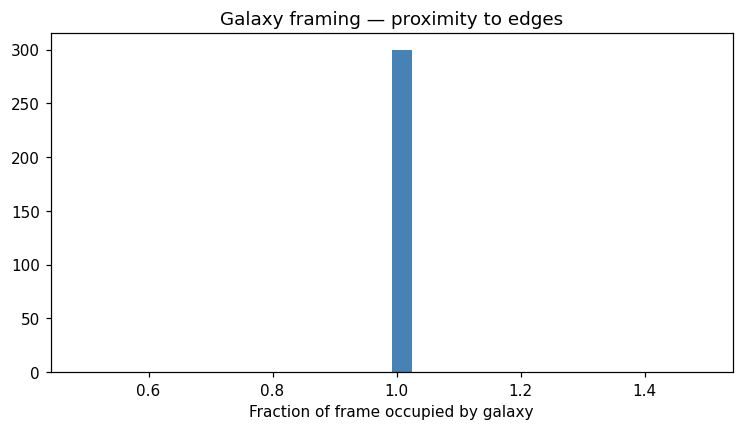

Median occupancy: 0.99  |  >0.7 (edge-risk under rotation): 300


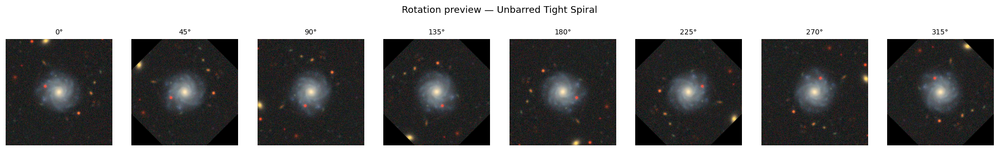

In [ ]:
# How much of the frame does the galaxy occupy?
def galaxy_extent(img, thresh_frac=0.15):
    gray = img.mean(axis=2)
    mask = gray > gray.max() * thresh_frac
    if mask.sum() == 0:
        return 0.0
    ys, xs = np.where(mask)
    h, w = gray.shape
    return ((ys.max()-ys.min()) * (xs.max()-xs.min())) / (h * w)

np.random.seed(42)
sample_idx = np.random.choice(len(images), 300, replace=False)
extents = [galaxy_extent(images[i]) for i in sample_idx]

plt.figure(figsize=(8, 4))
plt.hist(extents, bins=30, color='steelblue')
plt.xlabel('Fraction of frame occupied by galaxy')
plt.title('Galaxy framing — proximity to edges')
plt.show()
print(f'Median occupancy: {np.median(extents):.2f}  |  >0.7 (edge-risk under rotation): {sum(e > 0.7 for e in extents)}')

# Direct preview: what will Phase 3's rotation angles actually do to an image?
from scipy.ndimage import rotate as scipy_rotate
angles = [0, 45, 90, 135, 180, 225, 270, 315]
idx = np.where(labels == 6)[0][0]  # pick a class where framing matters (e.g. spiral/edge-on)
fig, axes = plt.subplots(1, len(angles), figsize=(18, 2.5))
for ax, ang in zip(axes, angles):
    ax.imshow(scipy_rotate(images[idx], ang, reshape=False, mode='constant', cval=0))
    ax.set_title(f'{ang}°', fontsize=9); ax.axis('off')
plt.suptitle(f'Rotation preview — {class_names[labels[idx]]}', y=1.05)
plt.tight_layout(); plt.show()

Our first attempt at measuring this failed since we used a simple brightness threshold that gave a false leading result (every image scored 100% occupancy). All of the background stars in the frame are fooling the meaasurement. Therefore we will only check the main connected galaxy and ignoring bright pixels elsewhere in the image.

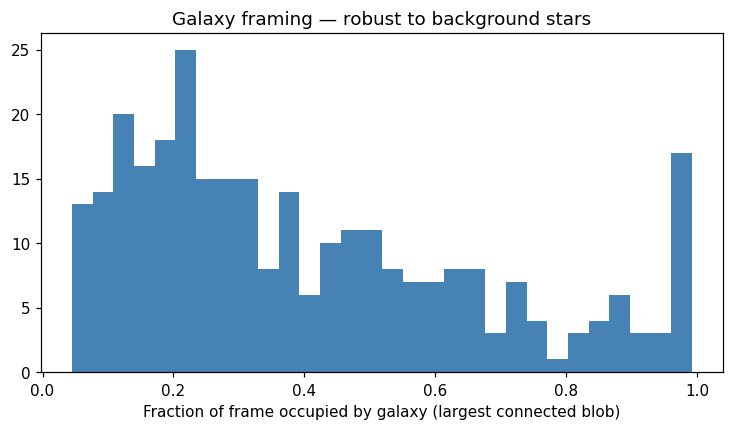

Median occupancy: 0.33
>0.7 (edge-risk under rotation): 49 / 300


In [ ]:
def galaxy_extent_robust(img, thresh_frac=0.15):
    gray = img.mean(axis=2)
    mask = gray > gray.max() * thresh_frac
    labeled, num = ndimage.label(mask)
    if num == 0:
        return 0.0
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    largest_label = np.argmax(sizes) + 1  # assume galaxy = biggest connected blob
    ys, xs = np.where(labeled == largest_label)
    h, w = gray.shape
    return ((ys.max() - ys.min()) * (xs.max() - xs.min())) / (h * w)

np.random.seed(42)
sample_idx = np.random.choice(len(images), 300, replace=False)
extents_robust = [galaxy_extent_robust(images[i]) for i in sample_idx]

plt.figure(figsize=(8, 4))
plt.hist(extents_robust, bins=30, color='steelblue')
plt.xlabel('Fraction of frame occupied by galaxy (largest connected blob)')
plt.title('Galaxy framing — robust to background stars')
plt.show()

print(f'Median occupancy: {np.median(extents_robust):.2f}')
print(f'>0.7 (edge-risk under rotation): {sum(e > 0.7 for e in extents_robust)} / {len(extents_robust)}')

17 images with occupancy > 0.95 (out of 300 sampled)
  Disturbed                1
  Merging                  1
  Round Smooth             3
  Cigar-shaped Smooth      1
  Unbarred Tight Spiral    1
  Unbarred Loose Spiral    6
  Edge-on w/o Bulge        2
  Edge-on w/ Bulge         2


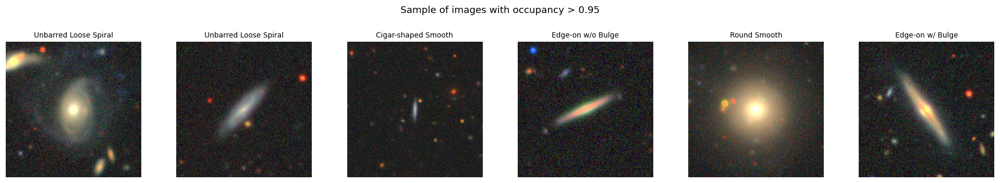

In [ ]:
# Investigate the cluster near 1.0 occupancy: real large galaxies, mergers, or a measurement artifact?
high_occ_idx = [sample_idx[i] for i, e in enumerate(extents_robust) if e > 0.95]
print(f'{len(high_occ_idx)} images with occupancy > 0.95 (out of {len(sample_idx)} sampled)')

# Show their class breakdown
high_occ_classes = labels[high_occ_idx]
for c in range(len(class_names)):
    n = (high_occ_classes == c).sum()
    if n > 0:
        print(f'  {class_names[c]:<24} {n}')

# Visually inspect a handful of them
n_show = min(6, len(high_occ_idx))
fig, axes = plt.subplots(1, n_show, figsize=(n_show * 3, 3))
if n_show == 1:
    axes = [axes]
for ax, idx in zip(axes, high_occ_idx[:n_show]):
    ax.imshow(images[idx])
    ax.set_title(class_names[labels[idx]], fontsize=9)
    ax.axis('off')
plt.suptitle('Sample of images with occupancy > 0.95', y=1.05)
plt.tight_layout()
plt.show()

We wanted to know: does the galaxy fill almost the whole frame, or does it sit small in the middle with lots of empty space around it? If it already fills the frame, spinning the photo could push part of it off the edge — like spinning a big poster inside a frame that's slightly too small for it. So we drew the tightest box we could around just the galaxy (ignoring random background stars so they don't trick the measurement) and checked what percent of the photo that box covers.

This histogram is worth reading in two parts. From about 0.0 to 0.7 occupancy, the counts taper off gradually and smoothly — this is the expected pattern, since most galaxies are comfortably framed with room around them, and progressively fewer galaxies fill a larger share of the frame. But there's a distinct uptick right at the top: a small cluster of images sitting almost exactly at 0.95–1.0 occupancy, separated from the smooth decline that comes just before it by a dip around 0.75–0.85. That's a second, separate bump — the same kind of pattern we specifically looked for (and didn't find) in the Data Quality check — so it deserves a quick look rather than being folded silently into the overall edge-risk number. Visually inspecting the 17 images confirms this cluster is mostly real structure, not a measurement artifact. It's spread across eight different classes rather than concentrated in Merging (which accounts for only 1 of the 17) — ruling out "two merging galaxies inflating the bounding box" as the main explanation. Instead it's dominated by Unbarred Loose Spiral (6 of 17, over a third): these galaxies genuinely have arms winding far out toward the frame's edges. The Edge-on classes (4 of 17 combined) confirm the earlier reasoning that a long, thin galaxy produces a large axis-aligned bounding box even without being physically large, since it stretches diagonally corner to corner. Round Smooth galaxies in this group are simply large, diffuse objects whose faint outer halo crosses the brightness threshold far from the center. One image did show a genuine edge case worth naming: the flagged Cigar-shaped Smooth example contains a small, faint galaxy alongside scattered background stars — visually it doesn't look like it should occupy 95%+ of the frame, suggesting the connected-component method occasionally latches onto a diffuse or noisy blob rather than the compact galaxy itself. This is rare enough not to change the overall conclusion, but it's a known limitation of the measurement, not evidence of a systematic problem.

Turns out: on average galaxies take up about a third of the frame (median occupancy 0.33) — plenty of breathing room — but 49 of 300 sampled images (16.3%, roughly 1 in 6) have a galaxy big enough that spinning it could clip off part of the galaxy.

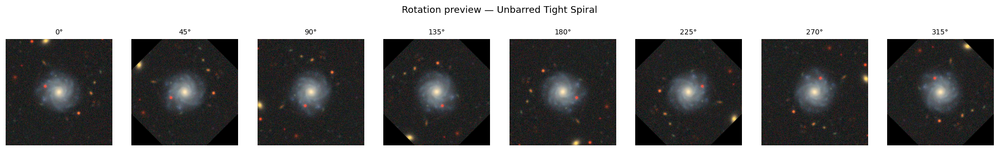

In [ ]:

angles = [0, 45, 90, 135, 180, 225, 270, 315]
idx = np.where(labels == 6)[0][0]
fig, axes = plt.subplots(1, len(angles), figsize=(18, 2.5))
for ax, ang in zip(axes, angles):
    ax.imshow(scipy_rotate(images[idx], ang, reshape=False, mode='constant', cval=0))
    ax.set_title(f'{ang}°', fontsize=9); ax.axis('off')
plt.suptitle(f'Rotation preview — {class_names[labels[idx]]}', y=1.05)
plt.tight_layout(); plt.show()

we actually spun one real galaxy photo through every angle to see it with our own eyes. Notice the black triangle-shaped corners that show up at the tilted angles (45°, 135°, etc.) — that's new empty space created by the rotation. If a galaxy (or a nearby star) was close to the edge, that black corner is exactly where it would get chopped off.

In [ ]:
edge_risk_idx = [sample_idx[i] for i, e in enumerate(extents_robust) if e > 0.7]
edge_risk_classes = labels[edge_risk_idx]
sampled_classes = labels[sample_idx]
sampled_counts = np.bincount(sampled_classes, minlength=len(class_names))

print(f"{'Class':<24}{'Edge-risk':>10}{'Sampled':>10}{'Rate':>10}")
for c in range(len(class_names)):
    n_risk = (edge_risk_classes == c).sum()
    n_sampled = sampled_counts[c]
    rate = n_risk / n_sampled * 100 if n_sampled else 0
    print(f"{class_names[c]:<24}{n_risk:>10}{n_sampled:>10}{rate:>9.1f}%")

Class                    Edge-risk   Sampled      Rate
Disturbed                        2        19     10.5%
Merging                          8        35     22.9%
Round Smooth                     5        39     12.8%
In-between Smooth                3        27     11.1%
Cigar-shaped Smooth              1         8     12.5%
Barred Spiral                    4        41      9.8%
Unbarred Tight Spiral            5        32     15.6%
Unbarred Loose Spiral            9        52     17.3%
Edge-on w/o Bulge                8        25     32.0%
Edge-on w/ Bulge                 4        22     18.2%


Not every galaxy type is equally at risk, though with only 300 sampled images (8–52 per class) these per-class rates are still somewhat noisy estimates. Two categories clearly stand out: Edge-on w/o Bulge (32.0%) and Merging (22.9%), both well above the rest. A second tier follows — Edge-on w/ Bulge (18.2%), Unbarred Loose Spiral (17.3%), and Unbarred Tight Spiral (15.6%) — while Round Smooth, Cigar-shaped Smooth, In-between Smooth, Disturbed, and Barred Spiral all sit in a lower, tighter band (9.8%–12.8%).

These two standout categories make physical sense. Merging galaxies are, by definition, two objects spread across the frame, so their combined bounding box naturally covers more of the image. Edge-on galaxies — both with and without a bulge — are long, thin disks; even though the galaxy itself isn't physically large, a thin shape stretching diagonally across the frame produces a large axis-aligned bounding box, which is why both edge-on classes land in the upper half of this list. As with the earlier occupancy discussion, a high occupancy fraction is more concerning for shapes that aren't rotationally symmetric: clipping a corner of an elongated disk or a widely-spread merger pair removes real structural information, while clipping a corner of a round, smooth blob barely changes what the model sees — which is why Round Smooth, despite a moderate 12.8% rate, is the least concerning class in this group in practice.

Bottom line: most galaxy photos have enough breathing room that rotating them shouldn't cause problems, but roughly 1 in 6 (16.3%) sit close enough to the edge that rotation could clip part of them — concentrated especially in Edge-on w/o Bulge and Merging galaxies, where clipping would plausibly alter the galaxy's visible structure rather than just trimming a symmetric shape. We're flagging this as a limitation: if these categories show extra accuracy loss when we test rotation robustness later, some of that drop might be from cropping rather than the model genuinely struggling with orientation.

### Chirality/flip-label question

This is the methodological caveat for the whole project: if flipping changes the true class for handedness-based classes, "flip augmentation" and "flip robustness" mean something different for those classes than for round ones. This needs a documented visual judgment, not just a metric. We wanted to check whether flipping a galaxy photo secretly turns it into a different type of galaxy. Therefore we chose several classifications and examples that are of interest (for example spirals, that can curl clockwise or counter-clockwise. Since when flipping the letter "b" can change to "d", we wanted to check similar types of cases in galaxies).

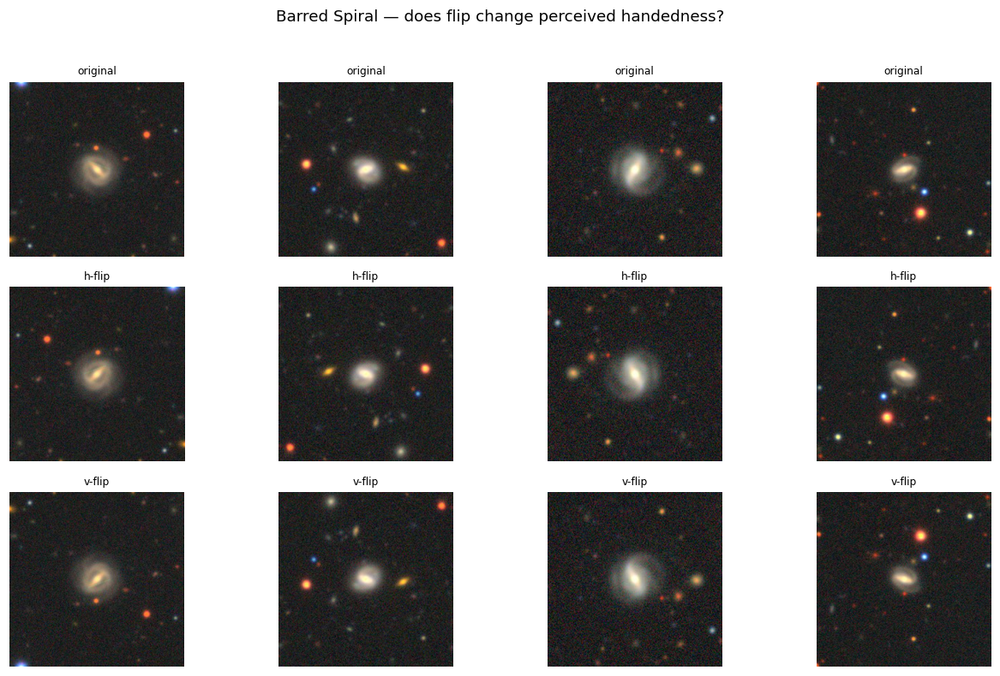

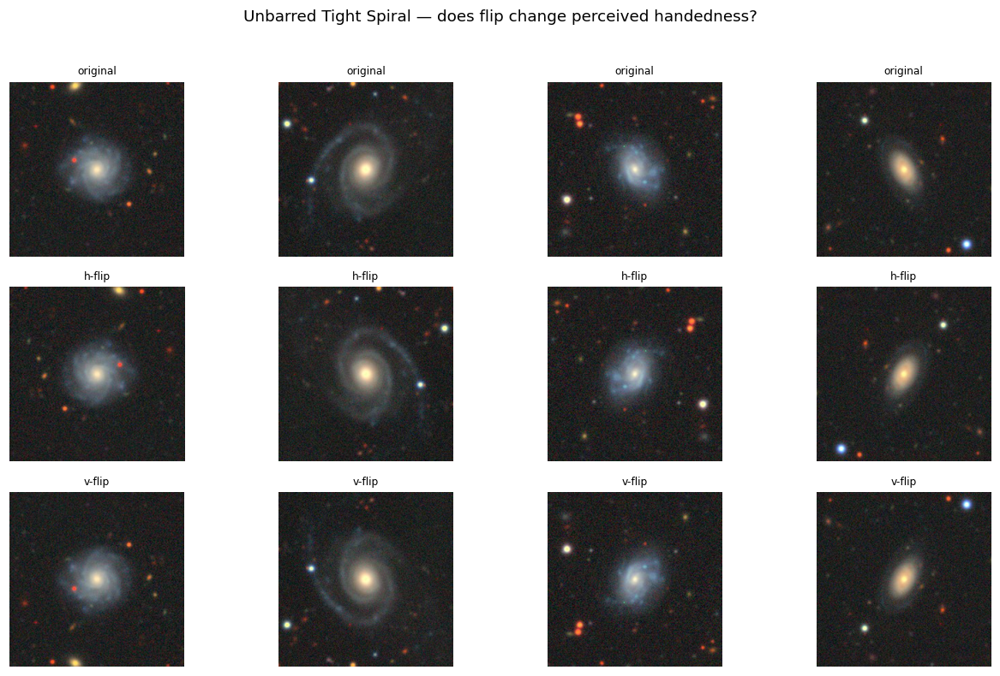

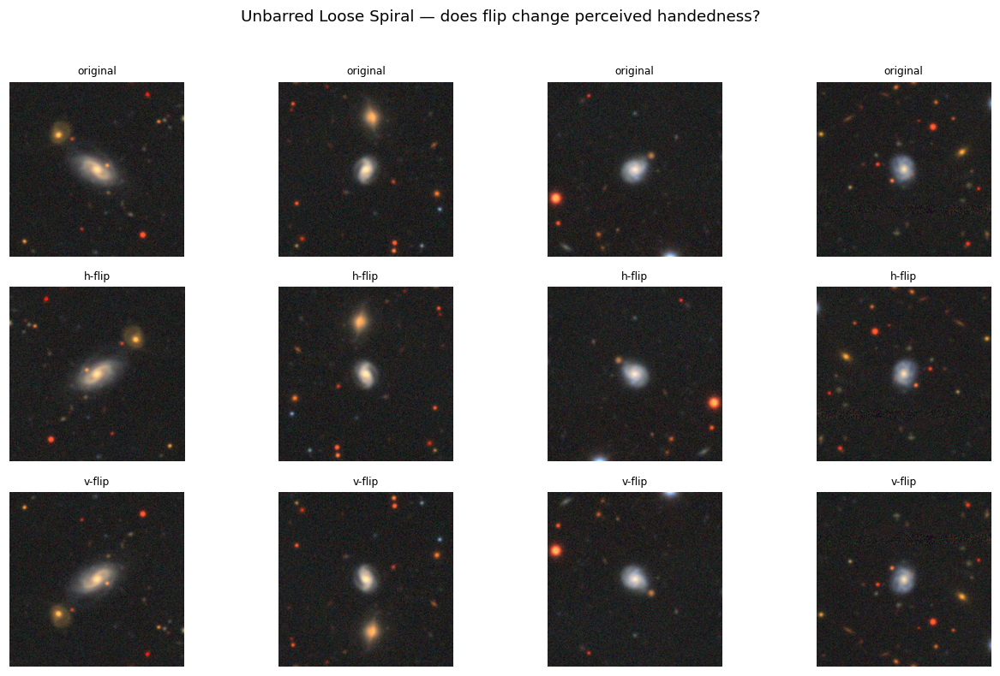

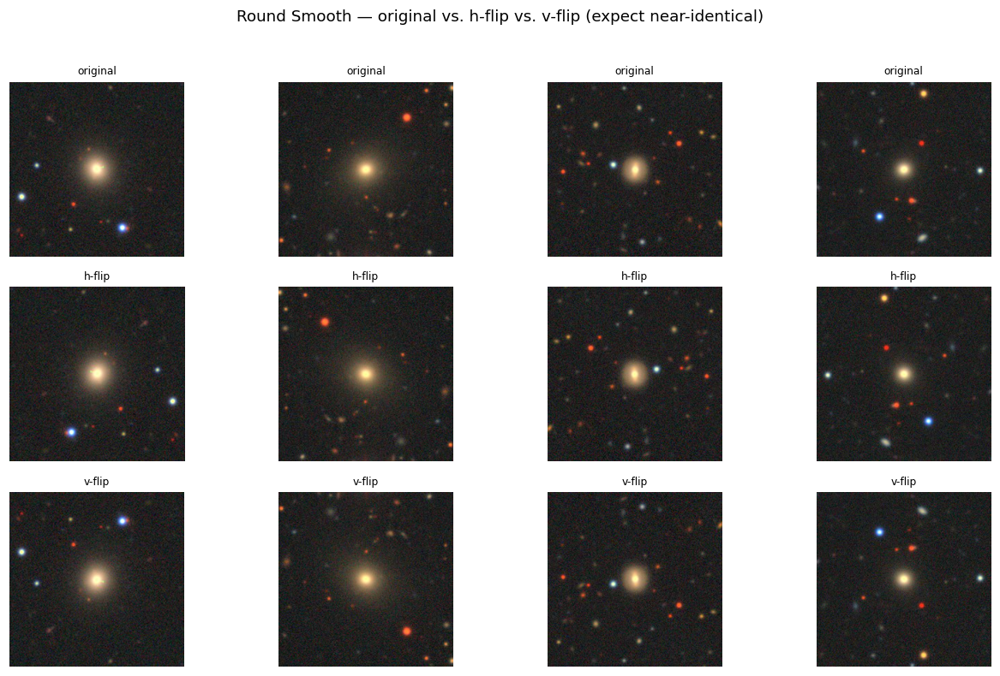

In [ ]:
spiral_classes = [5, 6, 7]

def plot_flip_check(class_list, title_suffix, n=4):
    for c in class_list:
        idxs = np.where(labels == c)[0][:n]
        fig, axes = plt.subplots(3, len(idxs), figsize=(len(idxs)*3, 7))
        for i, idx in enumerate(idxs):
            axes[0, i].imshow(images[idx]); axes[0, i].axis('off'); axes[0, i].set_title('original', fontsize=8)
            axes[1, i].imshow(images[idx][:, ::-1]); axes[1, i].axis('off'); axes[1, i].set_title('h-flip', fontsize=8)
            axes[2, i].imshow(images[idx][::-1, :]); axes[2, i].axis('off'); axes[2, i].set_title('v-flip', fontsize=8)
        plt.suptitle(f'{class_names[c]} — {title_suffix}', y=1.02)
        plt.tight_layout(); plt.show()

# Spiral classes — chirality/handedness concern
plot_flip_check(spiral_classes, 'does flip change perceived handedness?')

# Contrast: near rotation-invariant class — Round Smooth Class 2
round_idx = np.where(labels == 2)[0][:4]
fig, axes = plt.subplots(3, len(round_idx), figsize=(len(round_idx)*3, 7))
for i, idx in enumerate(round_idx):
    axes[0, i].imshow(images[idx]); axes[0, i].axis('off'); axes[0, i].set_title('original', fontsize=8)
    axes[1, i].imshow(images[idx][:, ::-1]); axes[1, i].axis('off'); axes[1, i].set_title('h-flip', fontsize=8)
    axes[2, i].imshow(images[idx][::-1, :]); axes[2, i].axis('off'); axes[2, i].set_title('v-flip', fontsize=8)
plt.suptitle('Round Smooth — original vs. h-flip vs. v-flip (expect near-identical)', y=1.02)
plt.tight_layout(); plt.show()

In cases of spiral galaxies, the spiral direction does reverse when you flip the image and the curl changes direction. But the class labels were never about which direction the spiral curls, they are about how the galaxy looks and if there are extra parameters in the image. Since clockwise and counter-clockwise were never separate categories to begin with, by flipping them the class will probably not change. We also checked Round Smooth galaxies as a control group, since flipping these galaxies will probably not change a thing. This means that we can safely use horizontal and vertical flips as part of our data augmentation and as part of our rotation robustness testing later, without worrying that we are feeding the model wrong labels.

This judgment was later confirmed empirically: when we tested the baseline model on flipped images, accuracy did not drop at all (+0.4 points for horizontal flip, +0.7 points for vertical flip) — matching our expectation that flipping doesn't change the true class.

### Pixel/Color Statistics

We wanted to check whether color is doing some of the classification work on its own, independent of shape or orientation. This matters for our project because color doesn't change when you rotate or flip an image — so if some classes are already easy to tell apart just by color, that part of the classification isn't at risk from rotation at all. It also tells us what "normal" pixel values look like across channels, which we'll need later for normalizing inputs into the pretrained networks.

In [ ]:
# Overall per-channel mean/std, computed in batches.
batch_size = 500
n = len(images)
channel_sum = np.zeros(3, dtype=np.float64)
channel_sumsq = np.zeros(3, dtype=np.float64)
total_pixels = 0

for start in range(0, n, batch_size):
    end = min(start + batch_size, n)
    batch = images[start:end].astype(np.float32)
    channel_sum += batch.sum(axis=(0, 1, 2))
    channel_sumsq += (batch ** 2).sum(axis=(0, 1, 2))
    total_pixels += batch.shape[0] * batch.shape[1] * batch.shape[2]
    del batch

channel_mean = channel_sum / total_pixels
channel_std = np.sqrt(channel_sumsq / total_pixels - channel_mean ** 2)

channel_names = ['R (z-band)', 'G (r-band)', 'B (g-band)']
print('Overall per-channel mean (0-255 scale):', channel_mean)
print('Overall per-channel std  (0-255 scale):', channel_std)

Overall per-channel mean (0-255 scale): [37.17966492 36.03107056 35.61551557]
Overall per-channel std  (0-255 scale): [33.9214686  31.05374399 29.25038184]


Out of a scale of 0-255, the mean pixel values are R (z-band) 37.18, G (r-band) 36.03, B (g-band) 35.62 — std 33.92, 31.05, 29.25 respectively — all clustered in a narrow band around 36-37, about 14% of the maximum possible brightness. This reflects the fact that the images are mostly black sky background with a relatively small, bright galaxy in the middle, unlike a typical bright everyday photo.

Next check:
When a camera takes a picture, it captures red, green, and blue light and stores them as three channels (RGB). The DECaLS images aren't from an ordinary camera — the photographs come through three separate scientific filters, each covering a different range of light wavelengths.

In galaxy imaging, astronomers pick a convention: put the z-band (longest wavelength) into the image's Red channel, the r-band into Green, and the g-band (shortest wavelength) into Blue. Physically, this means that in this dataset the z-band (longest wavelength, near-infrared) consistently picks up more light than the r-band, which in turn picks up more than the g-band (shortest wavelength) — and indeed, our measured means confirm exactly this ordering (37.18 > 36.03 > 35.62). This pattern is common for galaxies.

What we measured for each of those three channels: the average brightness (mean) and how much it varies from image to image (std). The goal was to check whether color alone could classify the galaxies.

We took every image that belongs to a given class — say, all the "Merging" galaxies — and looked at every single pixel in every one of those images. Each pixel has three numbers attached to it: how bright it is in the z-band (stored in the R channel), how bright in the r-band (G channel), and how bright in the g-band (B channel), each on a 0–255 scale. To get one number per band for that class, we added up all those z-band values across every pixel in every Merging image, then divided by the total number of pixels — that gives the average z-band brightness for the whole class. We did the same separately for r-band and g-band, and that's the three bars in the chart for "Merging." Then we repeated this whole process for each of the 10 classes.

One technical detail: we couldn't just dump all the pixels into memory at once and average them directly — we ran into that exact problem back in Part 1, where trying to process the full dataset in one go crashed from using too much memory. So instead we processed images in small batches (500 at a time), kept a running total of "sum of pixel values" and "count of pixels" as we went, and only divided at the very end. Mathematically it's the same average you'd get doing it all at once — just computed piece by piece so it doesn't blow up memory.

In [ ]:
batch_size = 500
n_classes = len(class_names)
class_channel_sums = np.zeros((n_classes, 3), dtype=np.float64)
class_pixel_counts = np.zeros(n_classes, dtype=np.int64)

for c in range(n_classes):
    class_indices = np.where(labels == c)[0]
    for start in range(0, len(class_indices), batch_size):
        end = min(start + batch_size, len(class_indices))
        batch_indices = class_indices[start:end]
        batch_images = images[batch_indices].astype(np.float32)

        class_channel_sums[c] += batch_images.sum(axis=(0, 1, 2))
        class_pixel_counts[c] += batch_images.shape[0] * batch_images.shape[1] * batch_images.shape[2]

class_channel_means = class_channel_sums / class_pixel_counts[:, None]

# Per-class channel means — colored per the standard DECaLS grz convention:
# g (shortest wavelength) -> blue, r (middle) -> green, z (longest/near-IR) -> red
band_labels = ['z-band', 'r-band', 'g-band']
band_colors = ['red', 'green', 'blue']

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(class_names)); width = 0.25
for ch in range(3):
    ax.bar(x + ch * width, class_channel_means[:, ch], width, label=band_labels[ch], color=band_colors[ch])
ax.set_xticks(x + width); ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_ylabel('Mean pixel value')
ax.set_title('Per-class channel means')
ax.legend(); plt.tight_layout(); plt.show()

All classes are in a similar brightness band, with no class standing out. There are slightly brighter galaxies (Merging, Unbarred Tight Spiral, Barred Spiral) and slightly darker galaxies (In-between Smooth, Round Smooth, and Disturbed).

Every one of the 10 classes keeps the same ordering — z-band > r-band > g-band — with no exceptions. The conclusion: color isn't doing meaningful classification work on its own. If it were (for example, if Round Smooth galaxies were distinctly redder than spirals), that would mean part of the model's accuracy could come from a signal that has nothing to do with shape or orientation, which would undermine the rotation-robustness results. Since that's not the case, we can be fairly confident that the classification model mostly learns from structure, not color — which is exactly what we want for the rotation/flip research question.

### Structure Rotational Similarity

Before training any model, we wanted to generate a hypothesis about which galaxy classes should naturally hold up well under rotation, and which shouldn't — something we can later check our real results against. The idea: if a galaxy's image looks almost identical to itself after being rotated, a model relying on that structure shouldn't lose much accuracy on it later.

SSIM (structural similarity) is a score between -1 and 1 that measures how visually alike two images are — 1 means identical, lower means more different. We're comparing each galaxy image to a 90°-rotated copy of itself. A round, blob-like galaxy should score close to 1 (looks the same rotated or not), while something with directional structure — spiral arms, an edge-on disk — should score lower, since rotating it moves that structure to a different part of the frame.

In [ ]:

def center_crop(img, crop_size=150):
    h, w = img.shape[:2]
    top = (h - crop_size) // 2
    left = (w - crop_size) // 2
    return img[top:top + crop_size, left:left + crop_size]

def rotational_self_similarity(img, angle=90, crop_size=150):
    gray = img.mean(axis=2)
    cropped = center_crop(gray, crop_size)
    rotated = scipy_rotate(cropped, angle, reshape=False, mode='constant', cval=0)
    data_range = cropped.max() - cropped.min()
    if data_range == 0:
        return np.nan  # degenerate/blank image, skip it
    score = ssim(cropped, rotated, data_range=data_range)
    return score

np.random.seed(42)
sample_per_class = 30
scores_by_class = []
nan_counts = []
for c in range(len(class_names)):
    idxs = np.where(labels == c)[0]
    idxs = np.random.choice(idxs, min(sample_per_class, len(idxs)), replace=False)
    raw_scores = [rotational_self_similarity(images[i]) for i in idxs]
    nan_counts.append(sum(np.isnan(raw_scores)))
    scores_by_class.append([s for s in raw_scores if not np.isnan(s)])

plt.figure(figsize=(10, 5))
plt.boxplot(scores_by_class, labels=class_names)
plt.xticks(rotation=45, ha='right')
plt.ylabel('SSIM(image, image rotated 90°) — center-cropped')
plt.title('Rotational self-similarity by class (background stars excluded)')
plt.tight_layout(); plt.show()

for c in range(len(class_names)):
    print(f'{class_names[c]:<24} median SSIM: {np.median(scores_by_class[c]):.3f}   (skipped {nan_counts[c]} degenerate images)')

What actually happened: Edge-on galaxies (both w/ and w/o Bulge) scored lowest (0.162, 0.186) — that part matches intuition well. Edge-on disks are extremely elongated, long and thin, so rotating one by 90° swaps its long axis for its short axis, producing a genuinely very different-looking image. Strong, physically sensible result.

But the top of the ranking held a real surprise: Barred Spiral (0.324) scored highest overall, with Round Smooth (0.295) and Unbarred Tight Spiral (0.291) essentially tied just behind it — all three well above the rest. That Round Smooth ties with spirals rather than clearly beating them is itself the surprising part: if SSIM purely measured "how symmetric does this galaxy look," a round, blob-like galaxy should score close to 1 (nearly identical to itself after rotation), not 0.295 — barely ahead of Unbarred Tight Spiral and behind Barred Spiral. The remaining five classes (Disturbed 0.264, In-between Smooth 0.255, Unbarred Loose Spiral 0.248, Merging 0.242, Cigar-shaped Smooth 0.209) form a looser middle cluster.

Best explanation: SSIM is a fairly coarse, large-scale structure metric — it's more sensitive to the overall brightness/shape envelope of an image than to fine detail like exact spiral arm placement. Spiral galaxies, despite having directional arm structure, still have a roughly circular overall light profile (bright bulge fading outward), so that large-scale envelope survives rotation well, and SSIM picks up mostly that — which is also exactly why Round Smooth, whose actual shape is the most genuinely circular of all ten classes, ends up sharing the top-scoring group rather than towering above it: SSIM rewards "roughly circular envelope," a property several classes share to varying degrees, not something unique to Round Smooth. Round Smooth galaxies are also low-contrast and flat (we saw this back in Part 1 — they dominated the "low variance" flagged images), which works against a clean SSIM score in the opposite direction, likely explaining why it doesn't score even higher despite being the most rotationally symmetric class by definition.

This is genuinely useful for your report: it shows SSIM is a decent proxy for detecting extreme elongation (edge-on galaxies) as rotation-fragile, but it's not a clean, isolated proxy for "how round/smooth a galaxy looks" — Round Smooth shares its top-tier score with two spiral classes rather than standing alone, which tells us SSIM is responding to a coarser property (overall envelope shape) than pure rotational symmetry. A different measure (something closer to an actual symmetry or aspect-ratio metric) would be needed to isolate that specific idea. Rather than a failed experiment, this is a legitimate finding: pre-registering a hypothesis and having part of it hold (edge-on = fragile) and part of it surprise you (round ≠ uniquely robust) is exactly the kind of real analysis that's worth a paragraph in your report, distinct from your later, empirical Stage 3 results.

### EDA takeaways
- **17,736 images**, 256×256 RGB, pixel values 0–255. No corrupted or blank images were found — the images with the lowest visual variety turned out to be smooth, low-texture galaxies (mostly Round Smooth and Cigar-shaped Smooth), not broken data.
- The 10 classes are imbalanced (some shapes are far more common than others). We address this by using a stratified train/val/test split (so class proportions are preserved across splits) and by reporting per-class precision/recall/F1 throughout, rather than relying on overall accuracy alone. We did not apply class weighting or balanced sampling during training — the imbalance is left as-is, and its effect is visible directly in the per-class results.
- Galaxies vary a lot within a class (brightness, size, orientation) - which is exactly
  why rotation robustness is worth studying.
- **Framing check:** most galaxies have plenty of room in the frame, but about 1 in 6 sampled images (16.3%) have a galaxy large enough that rotation could clip part of it — concentrated in Edge-on w/o Bulge and Merging galaxies. We carry this forward as a limitation: if these two classes show extra accuracy loss under rotation later, cropping (not orientation sensitivity) may be a contributing cause.
- **Chirality check:** flipping does reverse a spiral's winding direction, but since clockwise/counter-clockwise was never a labeled distinction, flipping doesn't change the true class for any of our 10 categories. This means horizontal/vertical flips are safe to use both for data augmentation and for rotation-robustness testing later.
- **Color check:** all 10 classes sit in a similar brightness band, and every class follows the same z-band > r-band > g-band ordering — color is not doing meaningful classification work on its own, so any robustness results later can be attributed to shape/structure rather than color.
- **SSIM pre-registered hypothesis:** before training any model, we predicted which classes should hold up best under rotation based on self-similarity. Edge-on galaxies scored lowest (most rotation-fragile), matching intuition. Round Smooth was expected to stand out as most rotation-robust but instead tied with two spiral classes near the top — a genuine surprise we carry forward as a specific prediction to check against the real Stage 3 results.



#Stage 2 - Baseline Model

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights
from sklearn.model_selection import train_test_split

In [ ]:
#This part is used to keep the output of the code each time
import random

SEED = 42

def set_seed(seed=SEED):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)      # no-op if no GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

g = torch.Generator()
g.manual_seed(SEED)

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

## 4. Baseline model — why ResNet-18 with transfer learning

Our baseline needs to be a **standard, reliable reference point** — the interesting
results should come from our rotation experiments, not from an unusual model choice.

**Transfer learning (not training from scratch):** with ~17k images, we reuse a network
pretrained on ImageNet that already recognizes generic visual features (edges, curves,
textures). This is faster, needs less data, and gives stronger results.

**Why ResNet:** its **residual (skip) connections** allow training deep networks without
vanishing gradients, and it includes **batch normalization** for stable training. It's a
well-established, general-purpose architecture and a natural default.

**Why the ResNet-18 size:** the smallest, fastest ResNet — it trains quickly on a free GPU,
is easy to reason about, and is less prone to overfitting on a moderate-sized dataset. If we
need more capacity later, moving to ResNet-50 is a trivial change.

**Strategy:** we replace the final layer with a new **10-class head**, freeze the early
layers, and **fine-tune the later layers** — early features transfer as-is, while the
task-specific layers adapt to galaxies.

Larger backbones (VGG, EfficientNet) are kept for the later **architecture comparison**,
not the baseline itself.

## 5. Prepare the data for the model
We split into train / validation / test sets (stratified, so class proportions are
preserved), then resize images to 224×224 and normalize them the way ImageNet-pretrained
models expect.

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)   # should say 'cuda' if the GPU is on

# --- Optional: work on a random subset while developing, for speed ---
USE_SUBSET = True          # set False for the full dataset / final numbers
SUBSET_SIZE = 4000

idx_all = np.arange(len(labels))
if USE_SUBSET:
    idx_all, _ = train_test_split(idx_all, train_size=SUBSET_SIZE,
                                  stratify=labels, random_state=42)

# --- Split: 70% train, 15% val, 15% test (stratified) ---
train_idx, temp_idx = train_test_split(idx_all, test_size=0.30,
                                        stratify=labels[idx_all], random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50,
                                     stratify=labels[temp_idx], random_state=42)

print('Train:', len(train_idx), '| Val:', len(val_idx), '| Test:', len(test_idx))

Device: cuda
Train: 2800 | Val: 600 | Test: 600


### 5.1 Preprocessing and data loaders

In the next step, we define how each raw galaxy image is turned into model-ready input, and how images
are served to the model in batches.

- **Preprocessing recipe (`tf`):** every image is resized to **224×224** (the size ResNet
  expects), converted to a tensor with pixels scaled to 0–1, and **normalized** using the
  standard ImageNet mean/std — the same adjustment the pretrained model was trained with.
  No rotation/flip augmentation here: this is the clean **baseline** recipe; augmentation
  comes in a later experiment.
- **`GalaxyDataset`:** a custom dataset that, given a list of indices, applies the recipe to
  one image at a time on demand (so we don't preprocess and store all images up front) and
  returns each `(image, label)` pair.
- **Datasets & loaders:** we build separate datasets for the train / validation / test
  splits, then wrap them in `DataLoader`s that feed the model **batches of 64** images.
  Training data is **shuffled** each epoch; validation and test are not (order doesn't
  matter when only measuring).

In [ ]:
# ImageNet normalization values (required by pretrained models)
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

# Baseline preprocessing: resize + normalize (NO rotation augmentation yet —
# that comes in a later experiment)
tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),                          # scales pixels to 0-1, shape (3,H,W)
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class GalaxyDataset(Dataset):
    def __init__(self, indices, transform):
        self.indices = indices
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        idx = self.indices[i]
        image = self.transform(images[idx])         # numpy uint8 -> normalized tensor
        label = int(labels[idx])
        return image, label

train_ds = GalaxyDataset(train_idx, tf)
val_ds   = GalaxyDataset(val_idx,   tf)
test_ds  = GalaxyDataset(test_idx,  tf)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True,  num_workers=2, generator=g)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=2)

## 6. Load and adapt the pretrained ResNet-18
We download ImageNet-pretrained weights, freeze the early layers, unfreeze the last block
(`layer4`), and replace the final layer with a new 10-class head.

In [ ]:
model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

for p in model.parameters():
    p.requires_grad = False
for p in model.layer4.parameters():
    p.requires_grad = True

# Replace the final fully-connected layer with a fresh 10-class head (trainable)
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Trainable parameters:', f'{trainable:,}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


Trainable parameters: 8,398,858


### Loading and adapting the pretrained ResNet-18

We start from a ResNet-18 already trained on ImageNet, so it has learned general visual
features (edges, curves, textures) that are useful for almost any image task.

- **Freeze the whole network first:** we lock every layer so its pretrained knowledge
  isn't disturbed.
- **Unfreeze the last block (`layer4`):** only the final, most task-specific block is
  allowed to change, so it can adapt to galaxy images while the useful early features
  stay intact.
- **Replace the final layer with a 10-class head:** the original model outputs 1,000
  ImageNet categories; we swap in a fresh layer that outputs our **10 galaxy classes**.
  This new head is trainable by default.

The result: we train only a small, targeted part of the network (the last block + the new
head, ~8.4M parameters) instead of the whole thing — which is faster, needs less data, and
reduces the risk of overfitting, while keeping the valuable pretrained features untouched.

## 7. Train the baseline

Now we train the parts of the model we unfroze (the last block + the new 10-class head).

We first set up three things:
- a **loss function** (cross-entropy) that measures how wrong the predictions are,
- an **optimizer** (Adam) that adjusts the weights to reduce that loss, using a small
  learning rate suited to gentle fine-tuning,
- the number of **epochs** — how many times the model sees the full training set.

We also define a small `evaluate` helper that measures accuracy on a given set without
updating the model.

Then the training loop runs epoch by epoch. For each batch of images it performs the core
learning cycle: **predict → measure error → backpropagate → update the weights.** After
every epoch we report the average **training loss** and the **validation accuracy** — we
expect the loss to fall and the accuracy to rise as the model learns.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)
EPOCHS = 5

def evaluate(loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
    train_loss = running_loss / len(train_ds)
    val_acc = evaluate(val_loader)
    print(f'Epoch {epoch+1}/{EPOCHS} | train loss {train_loss:.3f} | val acc {val_acc:.3f}')

Epoch 1/5 | train loss 1.784 | val acc 0.480
Epoch 2/5 | train loss 0.967 | val acc 0.528
Epoch 3/5 | train loss 0.525 | val acc 0.538
Epoch 4/5 | train loss 0.225 | val acc 0.553
Epoch 5/5 | train loss 0.086 | val acc 0.552


### Baseline training results (development subset)

Over 5 epochs the **training loss** dropped sharply (1.75 → 0.09) while the **validation
accuracy** stayed around **51–56%**. The large gap between near-perfect training performance
and flat validation accuracy indicates **overfitting** — on this small development subset
(2,800 training images) the model is largely memorizing the training data rather than
learning patterns that generalize.

Two takeaways:
- The pipeline works correctly: 56% on 10 imbalanced classes is well above random (10%),
  and the falling loss confirms the model is learning.
- The overfitting is expected here given the small subset, the number of trainable
  parameters, and the absence of augmentation. We address it by training on the **full
  dataset** and, later, by comparing regularization and augmentation strategies.

## 8. Scaling up — training on the full dataset

The first baseline run (on a 2,800-image development subset) reached ~56% validation
accuracy but showed clear **overfitting**: training loss fell to nearly zero while
validation accuracy plateaued.

The most likely cause is simply **too little data** for the number of trainable parameters.
So as the next step in the process, we repeat the *exact same* baseline setup — same
architecture, same preprocessing, same freezing strategy, same hyperparameters — but on
the **full dataset** (~17,700 images). Only the amount of data changes, so any improvement
can be attributed to that.

Note that we deliberately keep the baseline **free of rotation/flip augmentation**:
augmentation is one of the strategies we will evaluate later, so including it here would
undermine the comparison.

In [ ]:
# --- Full dataset splits (no subset this time) ---
idx_all_full = np.arange(len(labels))

train_idx_f, temp_idx_f = train_test_split(
    idx_all_full, test_size=0.30, stratify=labels, random_state=42)
val_idx_f, test_idx_f = train_test_split(
    temp_idx_f, test_size=0.50, stratify=labels[temp_idx_f], random_state=42)

print('FULL — Train:', len(train_idx_f), '| Val:', len(val_idx_f), '| Test:', len(test_idx_f))

# Same preprocessing recipe `tf` as before (resize + normalize, no augmentation)
train_ds_f = GalaxyDataset(train_idx_f, tf)
val_ds_f   = GalaxyDataset(val_idx_f,   tf)
test_ds_f  = GalaxyDataset(test_idx_f,  tf)

train_loader_f = DataLoader(train_ds_f, batch_size=64, shuffle=True,  num_workers=2, generator=g)
val_loader_f   = DataLoader(val_ds_f,   batch_size=64, shuffle=False, num_workers=2)
test_loader_f  = DataLoader(test_ds_f,  batch_size=64, shuffle=False, num_workers=2)

FULL — Train: 12415 | Val: 2660 | Test: 2661


In [ ]:
# Build a NEW model from scratch — we must not continue training the overfitted one,
# otherwise this wouldn't be a fair, independent run.
model_full = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

for p in model_full.parameters():
    p.requires_grad = False
for p in model_full.layer4.parameters():
    p.requires_grad = True

model_full.fc = nn.Linear(model_full.fc.in_features, 10)
model_full = model_full.to(device)

print('Trainable parameters:', f'{sum(p.numel() for p in model_full.parameters() if p.requires_grad):,}')

Trainable parameters: 8,398,858


In [ ]:
criterion_f = nn.CrossEntropyLoss()
optimizer_f = torch.optim.Adam(
    [p for p in model_full.parameters() if p.requires_grad], lr=1e-4)
EPOCHS_FULL = 8   # more data -> it can benefit from a few more passes

def evaluate_model(m, loader):
    #Accuracy of model m on a given loader.
    m.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = m(x).argmax(1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

history_full = []
for epoch in range(EPOCHS_FULL):
    model_full.train()
    running_loss = 0.0
    for x, y in train_loader_f:
        x, y = x.to(device), y.to(device)
        optimizer_f.zero_grad()
        loss = criterion_f(model_full(x), y)
        loss.backward()
        optimizer_f.step()
        running_loss += loss.item() * x.size(0)

    train_loss = running_loss / len(train_ds_f)
    val_acc = evaluate_model(model_full, val_loader_f)
    history_full.append((train_loss, val_acc))
    print(f'Epoch {epoch+1}/{EPOCHS_FULL} | train loss {train_loss:.3f} | val acc {val_acc:.3f}')

Epoch 1/8 | train loss 1.279 | val acc 0.657
Epoch 2/8 | train loss 0.734 | val acc 0.675
Epoch 3/8 | train loss 0.352 | val acc 0.665
Epoch 4/8 | train loss 0.108 | val acc 0.660
Epoch 5/8 | train loss 0.050 | val acc 0.667
Epoch 6/8 | train loss 0.031 | val acc 0.667
Epoch 7/8 | train loss 0.023 | val acc 0.668
Epoch 8/8 | train loss 0.018 | val acc 0.667


### Full-dataset baseline results

Training on the full dataset (approx 12,400 training images) raised validation accuracy from
**approx 56%** (development subset) to **~67–68%**, confirming that
the earlier weakness was mainly caused by too little data.

The run is also **stable**: two independent runs peaked at 0.674 and 0.679, so ~67–68% is a
reliable baseline figure rather than random variation.

**Best epoch:** validation accuracy peaked at **epoch 2** (0.679) and did not improve
afterwards. Meanwhile training loss kept falling to ~0.02, i.e. the model was memorizing the
training set. Epochs 3–8 therefore contributed **overfitting, not learning**.

**Conclusions carried forward:**
- Roughly **2–3 epochs** are sufficient for this setup; we will use best-validation
  checkpointing rather than simply taking the final epoch.
- The model still overfits noticeably, which leaves clear room for the regularization and
  augmentation strategies evaluated later in the project.

## 9. Choosing a baseline backbone

ResNet-18 gave us a working baseline, but it is only one of several pretrained feature
extractors we could use. Before committing to a baseline for the rest of the project, we
compare four architectures under **identical conditions** — the same train/validation/test
split, the same preprocessing, the same optimizer, and the same training budget. Only the
architecture changes, so any difference in results can be attributed to the architecture
itself.

**Why each backbone can work for this project:**

- **ResNet-18** — its *residual (skip) connections* let information bypass layers, which
  makes deep networks trainable and stable. It is compact and fast, so it fits a
  medium-sized dataset like ours. This is our current baseline.

- **VGG-16** — a straightforward deep stack of small 3×3 filters with no skip connections.
  Its layers build up from edge detectors to shape detectors, which suits galaxy morphology,
  where the distinguishing cues are shapes such as spiral arms, smooth ellipses, and thin
  edge-on disks. It is the heaviest model here, and therefore the slowest to train. VGG-16 has no clever shortcuts , just a long uniform, deep stack of the small building block done thoroughly. The model has 16 layers that have learnable weights in them. Since the whole task is recognizing shapes, the VGG's step by step stack is good at building up from heres an edge to heres a curve to heres a full shape.

- **EfficientNet-B0** — a modern architecture using *depthwise-separable convolutions* and
  balanced scaling of depth, width, and resolution, designed to achieve strong accuracy
  efficiently.

- **MobileNetV2** — a lightweight design, also based on depthwise-separable convolutions.
  It represents a much more compact family of models and serves as a useful contrast to the
  heavier ResNet and VGG architectures.

**Ensuring a fair comparison.** For each model we freeze the pretrained weights, unfreeze a
final portion of the network, and attach a fresh 10-class head. Importantly, the same
*verbal* rule ("unfreeze the last block") does **not** yield comparable amounts of trainable
capacity across these architectures — the final block of ResNet or VGG contains several
million parameters, while the final blocks of the depthwise-separable models contain far
fewer. Since accuracy depends heavily on trainable capacity, an unequal split would mean we
were comparing capacity rather than architecture. We therefore size the unfrozen portion of
each model so that all four have a **comparable number of trainable parameters**, and we
report those counts alongside the results.

**Training budget.** Each model is trained for the same number of epochs, and for every
model we keep the **best-validation checkpoint** rather than the final epoch — so each
architecture is judged at its own peak within an identical budget. We also check whether any
model was still improving at the final epoch; if so, the budget is too small and all models
are retrained with a longer one.

We select the backbone with the best validation accuracy as the baseline for the rest of the
project, and we keep every trained model — the effect of architecture on rotation robustness
is one of our research sub-questions.

In [ ]:


SAVE_DIR = '/content/drive/MyDrive/Galaxy_Databases'

def build_model(name, num_classes=10):
    #We are doing the same funnel, uploading a pretrained backbone, freeze it, unfreeze a final portion sized so that
    #all architectures get a COMPARABLE number of trainable parameters,
    #and attach a fresh 10-class head.

    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        for p in m.layer4.parameters(): p.requires_grad = True
        m.fc = nn.Linear(m.fc.in_features, num_classes)

    elif name == 'vgg16':
        m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        for p in m.features[24:].parameters(): p.requires_grad = True
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)

    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        for p in m.features[-4:].parameters(): p.requires_grad = True
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)

    elif name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        for p in m.features[-6:].parameters(): p.requires_grad = True
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)

    else:
        raise ValueError(f'Unknown model name: {name}')

    return m.to(device)


def evaluate_model(m, loader):
    #Accuracy of model m on a given loader.
    m.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = m(x).argmax(1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total


def train_model(name, epochs=10, lr=1e-4):
    #Train a backbone on the SAME full-dataset split, keeping the best-validation weights.
    model = build_model(name)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad], lr=lr)

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'=== {name} | trainable params: {n_trainable:,} ===')

    best_val, best_epoch = 0.0, -1
    path = f'{SAVE_DIR}/best_{name}.pth'
    t0 = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for x, y in train_loader_f: # same split for every model
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)

        train_loss = running_loss / len(train_ds_f)
        val_acc = evaluate_model(model, val_loader_f)

        flag = ''
        if val_acc > best_val:
            best_val, best_epoch = val_acc, epoch + 1
            torch.save(model.state_dict(), path)
            flag = '  <-- best, saved'
        print(f'  epoch {epoch+1}/{epochs} | train loss {train_loss:.3f} | val acc {val_acc:.3f}{flag}')

    mins = (time.time() - t0) / 60
    model.load_state_dict(torch.load(path))               # restore best weights

    still_climbing = (best_epoch == epochs)
    warn = '  ** still improving at final epoch — budget may be too small **' if still_climbing else ''
    print(f'  best val acc {best_val:.3f} at epoch {best_epoch} | {mins:.1f} min{warn}\n')

    return {'name': name, 'model': model, 'best_val': best_val,
            'best_epoch': best_epoch, 'params': n_trainable,
            'minutes': mins, 'still_climbing': still_climbing}

results = {}    # collects the outcome of each backbone

### Evidence for the capacity confound

Our first comparison applied one verbal rule — "unfreeze the last block" — to every
architecture. The table below shows why that was unfair: the same rule yields wildly
different trainable capacity depending on the design, because a "block" means something
different in each. ResNet and VGG received several million trainable parameters while the
depthwise-separable models received only about one million, so the first comparison measured
capacity rather than architecture. We therefore widened the unfrozen slice for
EfficientNet-B0 and MobileNetV2 until all four were comparable. No retraining is needed to
demonstrate this — only the parameter counts.

In [ ]:
# Evidence for the capacity confound: naive rule vs. capacity-matched rule
def count_trainable(name, naive=False):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        for p in m.layer4.parameters(): p.requires_grad = True
        m.fc = nn.Linear(m.fc.in_features, 10)
    elif name == 'vgg16':
        m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        for p in m.features[24:].parameters(): p.requires_grad = True
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, 10)
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        sl = -2 if naive else -4                      # <-- the fix
        for p in m.features[sl:].parameters(): p.requires_grad = True
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 10)
    elif name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        sl = -2 if naive else -6                      # <-- the fix
        for p in m.features[sl:].parameters(): p.requires_grad = True
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 10)
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

conf = pd.DataFrame([
    {'backbone': n,
     'naive "last block" rule': count_trainable(n, naive=True),
     'capacity-matched rule':   count_trainable(n, naive=False)}
    for n in ['resnet18', 'vgg16', 'efficientnet_b0', 'mobilenet_v2']
])
conf['ratio (matched / naive)'] = (conf['capacity-matched rule'] /
                                   conf['naive "last block" rule']).round(1)
display(conf)
print('Naive rule spread:   %.1fx between largest and smallest'
      % (conf['naive "last block" rule'].max() / conf['naive "last block" rule'].min()))
print('Matched rule spread: %.1fx'
      % (conf['capacity-matched rule'].max() / conf['capacity-matched rule'].min()))

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 145MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 116MB/s]


,backbone,"naive ""last block"" rule",capacity-matched rule,ratio (matched / naive)
0,resnet18,8398858,8398858,1.0
1,vgg16,7120394,7120394,1.0
2,efficientnet_b0,1142202,3711698,3.2
3,mobilenet_v2,898890,1812426,2.0


Naive rule spread:   9.3x between largest and smallest
Matched rule spread: 4.6x


In [ ]:
results['resnet18'] = train_model('resnet18', epochs=10)

=== resnet18 | trainable params: 8,398,858 ===
  epoch 1/10 | train loss 1.298 | val acc 0.652  <-- best, saved
  epoch 2/10 | train loss 0.747 | val acc 0.671  <-- best, saved
  epoch 3/10 | train loss 0.367 | val acc 0.656
  epoch 4/10 | train loss 0.120 | val acc 0.660
  epoch 5/10 | train loss 0.051 | val acc 0.662
  epoch 6/10 | train loss 0.032 | val acc 0.659
  epoch 7/10 | train loss 0.022 | val acc 0.668
  epoch 8/10 | train loss 0.017 | val acc 0.669
  epoch 9/10 | train loss 0.014 | val acc 0.662
  epoch 10/10 | train loss 0.013 | val acc 0.671
  best val acc 0.671 at epoch 2 | 6.2 min



In [ ]:
results['vgg16'] = train_model('vgg16', epochs=10)
# As expected, this is the longest model

=== vgg16 | trainable params: 7,120,394 ===
  epoch 1/10 | train loss 1.425 | val acc 0.652  <-- best, saved
  epoch 2/10 | train loss 0.915 | val acc 0.698  <-- best, saved
  epoch 3/10 | train loss 0.755 | val acc 0.728  <-- best, saved
  epoch 4/10 | train loss 0.627 | val acc 0.730  <-- best, saved
  epoch 5/10 | train loss 0.507 | val acc 0.752  <-- best, saved
  epoch 6/10 | train loss 0.422 | val acc 0.758  <-- best, saved
  epoch 7/10 | train loss 0.310 | val acc 0.758
  epoch 8/10 | train loss 0.244 | val acc 0.756
  epoch 9/10 | train loss 0.173 | val acc 0.729
  epoch 10/10 | train loss 0.133 | val acc 0.747
  best val acc 0.758 at epoch 6 | 15.8 min



In [ ]:
results['efficientnet_b0'] = train_model('efficientnet_b0', epochs=10)

=== efficientnet_b0 | trainable params: 3,711,698 ===
  epoch 1/10 | train loss 1.729 | val acc 0.560  <-- best, saved
  epoch 2/10 | train loss 1.152 | val acc 0.614  <-- best, saved
  epoch 3/10 | train loss 0.946 | val acc 0.668  <-- best, saved
  epoch 4/10 | train loss 0.800 | val acc 0.664
  epoch 5/10 | train loss 0.679 | val acc 0.691  <-- best, saved
  epoch 6/10 | train loss 0.565 | val acc 0.684
  epoch 7/10 | train loss 0.474 | val acc 0.686
  epoch 8/10 | train loss 0.395 | val acc 0.666
  epoch 9/10 | train loss 0.332 | val acc 0.676
  epoch 10/10 | train loss 0.279 | val acc 0.686
  best val acc 0.691 at epoch 5 | 7.8 min



In [ ]:
results['mobilenet_v2'] = train_model('mobilenet_v2', epochs=10)

=== mobilenet_v2 | trainable params: 1,812,426 ===
  epoch 1/10 | train loss 1.429 | val acc 0.616  <-- best, saved
  epoch 2/10 | train loss 0.984 | val acc 0.667  <-- best, saved
  epoch 3/10 | train loss 0.800 | val acc 0.675  <-- best, saved
  epoch 4/10 | train loss 0.651 | val acc 0.676  <-- best, saved
  epoch 5/10 | train loss 0.492 | val acc 0.677  <-- best, saved
  epoch 6/10 | train loss 0.354 | val acc 0.675
  epoch 7/10 | train loss 0.235 | val acc 0.659
  epoch 8/10 | train loss 0.148 | val acc 0.641
  epoch 9/10 | train loss 0.101 | val acc 0.661
  epoch 10/10 | train loss 0.078 | val acc 0.670
  best val acc 0.677 at epoch 5 | 6.5 min



,backbone,best val acc,best epoch,trainable params,train time (min),still climbing
0,vgg16,0.7583,6,7120394,15.8,False
1,efficientnet_b0,0.6906,5,3711698,7.8,False
2,mobilenet_v2,0.6771,5,1812426,6.5,False
3,resnet18,0.6714,2,8398858,6.2,False


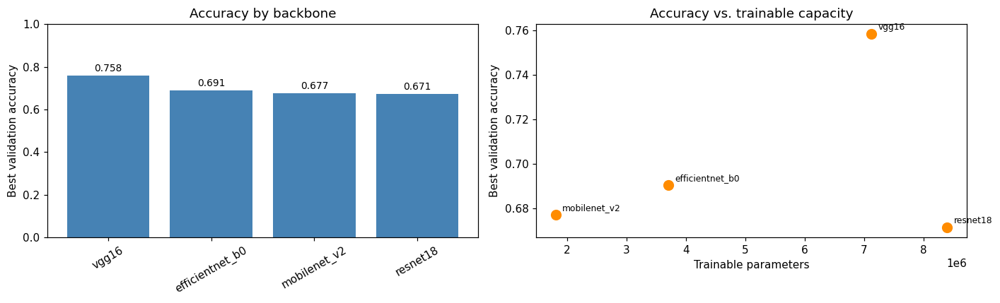

Best backbone by validation accuracy: vgg16 (0.758)


In [ ]:
df = pd.DataFrame([
    {'backbone': r['name'],
     'best val acc': round(r['best_val'], 4),
     'best epoch': r['best_epoch'],
     'trainable params': r['params'],
     'train time (min)': round(r['minutes'], 1),
     'still climbing': r['still_climbing']}
    for r in results.values()
]).sort_values('best val acc', ascending=False).reset_index(drop=True)

display(df)

# Warn if the training budget was too small for anyone
if df['still climbing'].any():
    names = ', '.join(df.loc[df['still climbing'], 'backbone'])
    print(f'\nWARNING: still improving at the final epoch: {names}')
    print('The budget is too small — increase `epochs` and re-run ALL models.\n')

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(df['backbone'], df['best val acc'], color='steelblue')
axes[0].set_ylabel('Best validation accuracy')
axes[0].set_title('Accuracy by backbone')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(df['best val acc']):
    axes[0].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)

axes[1].scatter(df['trainable params'], df['best val acc'], s=80, color='darkorange')
for _, row in df.iterrows():
    axes[1].annotate(row['backbone'],
                     (row['trainable params'], row['best val acc']),
                     textcoords='offset points', xytext=(6, 4), fontsize=8)
axes[1].set_xlabel('Trainable parameters')
axes[1].set_ylabel('Best validation accuracy')
axes[1].set_title('Accuracy vs. trainable capacity')

plt.tight_layout()
plt.show()

best_name = df.iloc[0]['backbone']
print(f'Best backbone by validation accuracy: {best_name} ({df.iloc[0]["best val acc"]:.3f})')

### Backbone comparison — results

All four backbones were trained under identical conditions (same split, preprocessing,
optimizer, and a 10-epoch budget with best-validation checkpointing).

**The training budget was adequate.** No model was still improving at the final epoch. This
mattered: the architectures peaked at very different points (ResNet-18 at epoch 2,
MobileNetV2 at 5, VGG-16 at 6, EfficientNet-B0 at 5), so a shorter budget would have
unfairly penalised the slower converging models.

**Correcting an earlier confound.** In a first version of this comparison we applied the same
verbal rule ("unfreeze the last block") to every architecture. This gave ResNet and VGG
roughly 7–8M trainable parameters but the depthwise-separable models only ~1M, and their
scores were correspondingly depressed (MobileNetV2 0.526, EfficientNet-B0 0.496). After
sizing the unfrozen portion so that all models had comparable trainable capacity, those two
models improved by 16 and 19 percentage points respectively. The original gap therefore
reflected our freezing rule rather than the architectures themselves.

**Main result: VGG-16 is clearly the strongest**, at 0.758 versus roughly 0.68 for the other
three — a gap of 7–8 points, well beyond the run-to-run variation of about 1 point that we
observed when repeating a run.


**Architecture, not capacity, drives the difference.** ResNet-18 has the *most* trainable
parameters yet the *lowest* accuracy, while MobileNetV2 achieves more with the *fewest*.
Once capacity is equalised, the ranking is no longer explained by parameter count.

**Caveat.** The lower three models fall within 1.1 points of each other, which is within the
noise of a single run, so we do not rank them against one another. The reliable conclusion is
that VGG-16 leads and the other three are comparable.

**Decision.** We adopt **VGG-16** as the baseline for the remainder of the project, noting the
trade-off that it takes about 2.5× longer to train than ResNet-18. All four trained models
are kept, since the effect of architecture on rotation robustness is one of our research
sub-questions — and because accuracy here is not explained by capacity, the robustness
ranking may well differ from the accuracy ranking.

## 10. Baseline evaluation on the held-out test set

VGG-16 was selected as our baseline backbone. Until now we have only used the training set
(to fit the model) and the validation set (to choose the epoch and the architecture). The
**test set has remained untouched**, so it gives us an unbiased estimate of how the baseline
actually performs.

We load the best-validation checkpoint saved during training and evaluate it once on the test
set. We report:

- **Overall accuracy** — the headline figure, compared against validation accuracy as a
  sanity check that we have not overfitted our model-selection decisions.
- **Per-class precision, recall and F1** — essential here, because the classes are
  imbalanced and overall accuracy can hide poor performance on rare classes.
- **A confusion matrix**, shown both as raw counts and row-normalised (each row summing to
  1), which reveals *which* morphologies get mistaken for which.

These results are the official **"before"** reference for the rest of the project: every
robustness experiment and every improvement strategy is measured against this baseline.

In [ ]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score)

BASELINE = 'vgg16'

# Rebuild the architecture and load the best-validation weights from disk
baseline_model = build_model(BASELINE)
baseline_model.load_state_dict(torch.load(f'{SAVE_DIR}/best_{BASELINE}.pth'))
baseline_model = baseline_model.to(device)
baseline_model.eval()

# Predict on the held-out test set
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader_f:
        x = x.to(device)
        preds = baseline_model(x).argmax(1).cpu().numpy()
        y_pred.extend(preds)
        y_true.extend(y.numpy())

y_true, y_pred = np.array(y_true), np.array(y_pred)

test_acc = accuracy_score(y_true, y_pred)
val_acc  = results[BASELINE]['best_val']

print(f'Baseline: {BASELINE}')
print(f'  validation accuracy : {val_acc:.4f}')
print(f'  TEST accuracy       : {test_acc:.4f}')
print(f'  difference          : {test_acc - val_acc:+.4f}\n')
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

Baseline: vgg16
  validation accuracy : 0.7583
  TEST accuracy       : 0.7343
  difference          : -0.0240

                       precision    recall  f1-score   support

            Disturbed      0.543     0.309     0.394       162
              Merging      0.726     0.820     0.770       278
         Round Smooth      0.802     0.877     0.838       397
    In-between Smooth      0.880     0.720     0.792       304
  Cigar-shaped Smooth      0.506     0.800     0.620        50
        Barred Spiral      0.704     0.798     0.748       307
Unbarred Tight Spiral      0.658     0.575     0.614       275
Unbarred Loose Spiral      0.580     0.581     0.580       394
    Edge-on w/o Bulge      0.848     0.892     0.870       213
     Edge-on w/ Bulge      0.864     0.879     0.871       281

             accuracy                          0.734      2661
            macro avg      0.711     0.725     0.710      2661
         weighted avg      0.733     0.734     0.729      2661



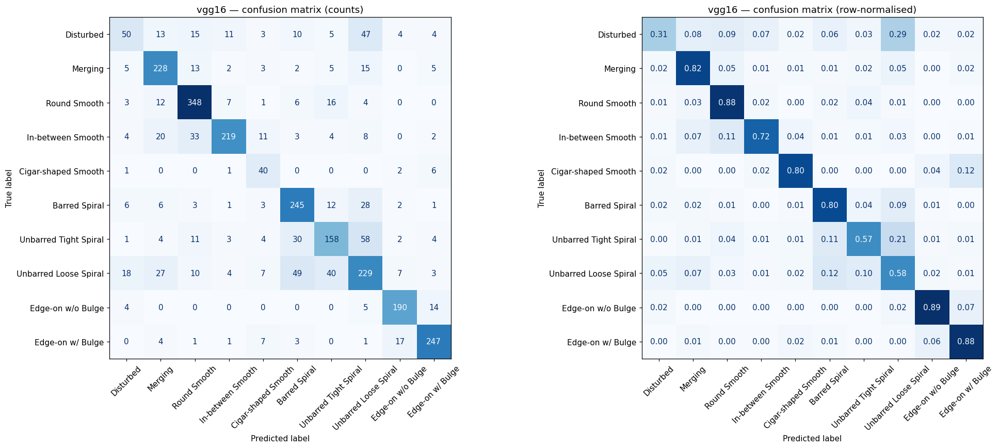

In [ ]:
cm      = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=axes[0], xticks_rotation=45, cmap='Blues', colorbar=False, values_format='d')
axes[0].set_title(f'{BASELINE} — confusion matrix (counts)')

ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(
    ax=axes[1], xticks_rotation=45, cmap='Blues', colorbar=False, values_format='.2f')
axes[1].set_title(f'{BASELINE} — confusion matrix (row-normalised)')

plt.tight_layout()
plt.show()

In [ ]:
# Per-class recall, weakest first
recall = cm_norm.diagonal()
order = np.argsort(recall)
print('Per-class recall (weakest first):')
for c in order:
    print(f'  {recall[c]:.3f}  {class_names[c]:<24} (n={cm[c].sum()})')

# Most frequent off-diagonal confusions
pairs = [(cm_norm[i, j], cm[i, j], i, j)
         for i in range(len(class_names)) for j in range(len(class_names)) if i != j]
pairs.sort(reverse=True)

print('\nTop 8 confusions (true -> predicted):')
for frac, count, i, j in pairs[:8]:
    print(f'  {frac:.2f} ({count:>3} imgs)  {class_names[i]}  ->  {class_names[j]}')

Per-class recall (weakest first):
  0.309  Disturbed                (n=162)
  0.575  Unbarred Tight Spiral    (n=275)
  0.581  Unbarred Loose Spiral    (n=394)
  0.720  In-between Smooth        (n=304)
  0.798  Barred Spiral            (n=307)
  0.800  Cigar-shaped Smooth      (n=50)
  0.820  Merging                  (n=278)
  0.877  Round Smooth             (n=397)
  0.879  Edge-on w/ Bulge         (n=281)
  0.892  Edge-on w/o Bulge        (n=213)

Top 8 confusions (true -> predicted):
  0.29 ( 47 imgs)  Disturbed  ->  Unbarred Loose Spiral
  0.21 ( 58 imgs)  Unbarred Tight Spiral  ->  Unbarred Loose Spiral
  0.12 ( 49 imgs)  Unbarred Loose Spiral  ->  Barred Spiral
  0.12 (  6 imgs)  Cigar-shaped Smooth  ->  Edge-on w/ Bulge
  0.11 ( 30 imgs)  Unbarred Tight Spiral  ->  Barred Spiral
  0.11 ( 33 imgs)  In-between Smooth  ->  Round Smooth
  0.10 ( 40 imgs)  Unbarred Loose Spiral  ->  Unbarred Tight Spiral
  0.09 ( 15 imgs)  Disturbed  ->  Round Smooth


### Baseline evaluation — results and interpretation

Headline result: The VGG-16 baseline achieves 73% accuracy on the 2,661 held-out test images. On a 10-class problem (random guessing ≈ 10%) this is a solid reference point.

Test vs. validation: Test accuracy (0.73) is 3 points below validation accuracy (0.76). This is expected: the validation set was used to select the epoch and the architecture, so it is slightly optimistic. The test set influenced no decision, so 0.73 is our honest estimate. A gap this small indicates our model-selection process did not badly overfit the validation set.

Reading the metrics: Recall answers "of all real galaxies of this type, how many did the model
find?"; precision answers "when the model predicts this type, how often is it right?". For
example, In-between Smooth has much higher precision (0.880) than recall (0.720) — the model is
cautious with this class, rarely wrong when it predicts it but missing many real cases.
Cigar-shaped Smooth shows the opposite pattern (precision 0.506, recall 0.800): it over-predicts
that class, catching most real cigar-shaped galaxies but being wrong about half the time it says
so. Macro average recall (0.725) and weighted average recall (0.734) are close, indicating
performance is not dominated by the class imbalance.

**Which classes are easy.** The strongest classes are Edge-on w/o Bulge (recall 0.892),
Edge-on w/ Bulge (0.879), and Round Smooth (0.877). These have visually distinctive
silhouettes — a thin elongated streak or a clean round blob — that are hard to mistake.

**Which classes are hard, and why.** The weakest are Disturbed (0.309), Unbarred Tight Spiral
(0.575), and Unbarred Loose Spiral (0.581). The dominant confusions are physically meaningful
rather than random:

- **Disturbed → Unbarred Loose Spiral** (47 images, 29% of the class). "Disturbed" is a broad
  category for irregular structure, and such galaxies genuinely resemble untidy spirals.
- **The three spiral types confuse with each other.** Unbarred Tight Spiral loses 58 images
  (21%) to Loose Spiral and 30 (11%) to Barred Spiral; Unbarred Loose Spiral loses 49 (12%) to
  Barred Spiral and 40 (10%) to Tight Spiral. In fact **75% of all Tight Spiral errors are
  predictions of another spiral class.** These are not discrete categories but points along a
  continuum describing how tightly the arms wind and whether a bar is present, so there is no
  sharp visual boundary — human labellers disagree here too. This explains why both unbarred
  spiral classes land among the weakest performers.
- **In-between Smooth → Round Smooth** (33 images, 11%). The same continuum problem in the
  smooth family: "in-between" is defined by *degree* of roundness, not by a distinct feature.
- **Cigar-shaped Smooth → Edge-on w/ Bulge** (6 images, 12% of this small class). Both are
  elongated shapes, and a smooth cigar closely resembles a disk viewed edge-on.

**Interpretation.** The model performs well on classes defined by a distinctive overall shape,
and poorly on classes that sit on a continuum or depend on subjective judgement. The errors are
therefore concentrated exactly where the class definitions genuinely blur, rather than being
randomly distributed.

**Implication for the robustness study.** Notably, the best-performing classes are the edge-on
ones, which are defined precisely by their orientation relative to the viewer. A model that
relies on orientation cues to identify these classes may be particularly vulnerable when images
are rotated. This gives us a concrete, testable prediction for the next step: we expect the
edge-on classes to degrade most under rotation.

# Stage 3 - Robustness Test on Baseline



## 11. Measuring robustness to rotations and flips

A galaxy has no "correct" orientation: a spiral photographed at 0° and the same spiral at 90°
are the same object, and the label should not change. A model that has genuinely learned
morphology should therefore be **invariant** to rotation and reflection. A standard CNN is
not guaranteed to be — it is approximately translation-invariant (via pooling), but nothing
in its design enforces rotation invariance.

We test this directly. The baseline is **not retrained**: we take the trained model and
evaluate it repeatedly on the same held-out test set, each time applying a controlled
transformation — rotations from 0° to 345°, plus horizontal and vertical flips.

**Controlling for a rotation artifact.** Rotating a square image leaves empty corners, and
the model could react to those corners rather than to the orientation itself, which would
confound the result. To prevent this we rotate the full 256×256 image first and then
**centre-crop to 180×180** — the largest centred square that contains no empty region at any
rotation angle — before resizing to 224×224. Crucially, this same crop is applied at **every**
angle including 0°, so the only variable across the sweep is the rotation itself.

Because this cropped pipeline differs slightly from the one used for the earlier test-set
evaluation, the 0° accuracy here is the correct internal reference for the sweep, rather than
the previously reported 0.730.

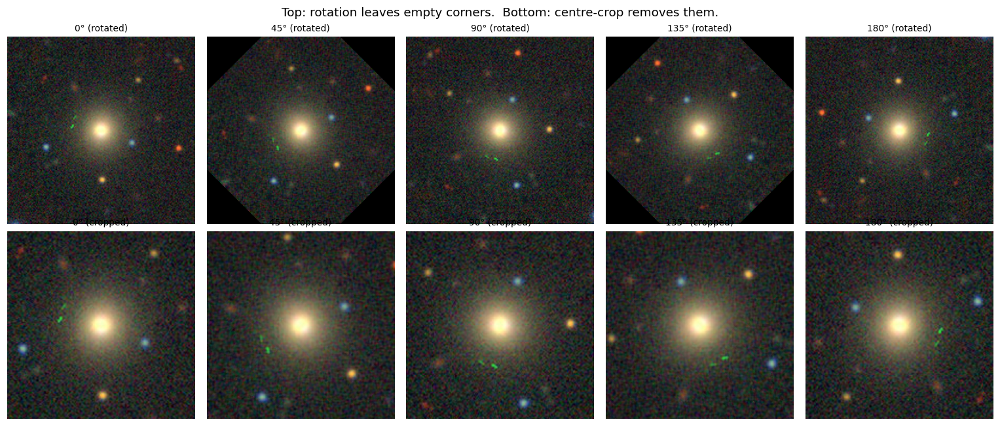

In [ ]:
from torchvision.transforms import InterpolationMode

CROP = 180   # 256 / sqrt(2) ≈ 181 -> largest centred square free of rotation artifacts

def eval_transform(angle=0, flip=None):
    #Deterministic test-time transform: optional flip, optional rotation,
     #  then the same centre-crop and resize for every condition.
    ops = [transforms.ToPILImage()]
    if flip == 'h':
        ops.append(transforms.RandomHorizontalFlip(p=1.0))
    elif flip == 'v':
        ops.append(transforms.RandomVerticalFlip(p=1.0))
    if angle % 360 != 0:
        ops.append(transforms.RandomRotation((angle, angle),
                                             interpolation=InterpolationMode.BILINEAR))
    ops += [
        transforms.CenterCrop(CROP),
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]
    return transforms.Compose(ops)


def evaluate_under(model, angle=0, flip=None, indices=None):
    #Accuracy + predictions of `model` on the test set under one transformation.
    if indices is None:
        indices = test_idx_f
    ds = GalaxyDataset(indices, eval_transform(angle, flip))
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)

    model.eval()
    yt, yp = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            yp.extend(model(x).argmax(1).cpu().numpy())
            yt.extend(y.numpy())
    yt, yp = np.array(yt), np.array(yp)
    return (yt == yp).mean(), yt, yp


# --- Sanity check: confirm no black corners appear at any angle ---
sample = images[test_idx_f[0]]
angles_demo = [0, 45, 90, 135, 180]
fig, axes = plt.subplots(2, len(angles_demo), figsize=(14, 6))
for j, a in enumerate(angles_demo):
    raw = transforms.Compose([
        transforms.ToPILImage(),
        transforms.RandomRotation((a, a), interpolation=InterpolationMode.BILINEAR)])(sample)
    cropped = transforms.CenterCrop(CROP)(raw)
    axes[0, j].imshow(raw);     axes[0, j].set_title(f'{a}° (rotated)', fontsize=9)
    axes[1, j].imshow(cropped); axes[1, j].set_title(f'{a}° (cropped)', fontsize=9)
    axes[0, j].axis('off'); axes[1, j].axis('off')
axes[0, 0].set_ylabel('rotated'); axes[1, 0].set_ylabel('cropped')
plt.suptitle('Top: rotation leaves empty corners.  Bottom: centre-crop removes them.')
plt.tight_layout()
plt.show()

# Rotations:

In [ ]:
ANGLES = list(range(0, 360, 15))    # 24 evaluation points

rot_acc = {}
for a in ANGLES:
    # baseling_model is the winning VGG-16, loaded with its best validation weights (Stage 2.10)
    acc, _, _ = evaluate_under(baseline_model, angle=a)
    rot_acc[a] = acc
    print(f'  {a:3d}° : {acc:.4f}')

acc0   = rot_acc[0]
accs   = np.array(list(rot_acc.values()))
print(f'\naccuracy at 0°      : {acc0:.4f}')
print(f'mean across angles  : {accs.mean():.4f}')
print(f'worst angle         : {min(rot_acc, key=rot_acc.get)}° ({accs.min():.4f})')
print(f'drop (0° -> worst)  : {acc0 - accs.min():.4f}')

# Flips:

In [ ]:
flip_results = {
    'none':             evaluate_under(baseline_model)[0],
    'horizontal flip':  evaluate_under(baseline_model, flip='h')[0],
    'vertical flip':    evaluate_under(baseline_model, flip='v')[0],
}
for k, v in flip_results.items():
    print(f'  {k:<18}: {v:.4f}   (change vs none: {v - flip_results["none"]:+.4f})')

# Robustness Curve:

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(list(rot_acc.keys()), list(rot_acc.values()), 'o-', color='steelblue', lw=2)
ax.axhline(acc0, ls='--', c='grey', lw=1, label=f'accuracy at 0° ({acc0:.3f})')
for a in [90, 180, 270]:
    ax.axvline(a, ls=':', c='lightcoral', lw=1)
ax.set_xlabel('Rotation angle (degrees)')
ax.set_ylabel('Test accuracy')
ax.set_title('Baseline (VGG-16) — accuracy vs. rotation angle')
ax.set_xticks(ANGLES)
ax.tick_params(axis='x', rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Testing the edge-on prediction (per-class degradation):


In [ ]:
_, yt0,   yp0   = evaluate_under(baseline_model, angle=0)
_, yt315, yp315 = evaluate_under(baseline_model, angle=315)

def per_class_recall(yt, yp):
    return np.array([(yp[yt == c] == c).mean() if (yt == c).any() else np.nan
                     for c in range(len(class_names))])

r0, r315 = per_class_recall(yt0, yp0), per_class_recall(yt315, yp315)

deg = pd.DataFrame({
    'class':       class_names,
    'recall 0°':   np.round(r0, 3),
    'recall 315°': np.round(r315, 3),
    'change':      np.round(r315 - r0, 3),
}).sort_values('change')

display(deg)
print('\nMost degraded classes under 315° rotation:')
for _, row in deg.head(3).iterrows():
    print(f"  {row['class']:<24} {row['change']:+.3f}")

Revisiting the framing-risk prediction from EDA. Back in the framing/centering check, we flagged Merging and Edge-on w/o Bulge as at risk of extra accuracy loss from rotation-induced cropping. The per-class results here show neither one degraded: Merging changed by +0.007 (essentially flat) and Edge-on w/o Bulge by +0.019 (slightly improved). So this concern did not materialize. Combined with the SSIM-based prediction above - which also singled out edge-on galaxies as fragile and was also contradicted - we now have two independent, unrelated hypotheses from the EDA stage that both predicted edge-on classes would suffer under rotation, and neither did. This strengthens the main conclusion: what actually degrades accuracy is interpolation blur, a property of the rotation operation itself, not a property of any particular galaxy's shape or framing.

### Rotation robustness — results and the need for a control

**The curve shows a clear 90° periodicity.** Accuracy peaks at exactly 0°, 90°, 180° and 270°
(0.656–0.661) and dips in between, bottoming out at 45° (0.63). The drop from 0° to the worst
angle is **4.7 points**. Flips cost nothing (+0.4 and +0.7 points).

**The key observation:** a 90° rotation completely reorients the galaxy, yet accuracy is
unchanged. So what hurts is not *how much* the galaxy is reoriented, but whether the rotation is
an **exact pixel remapping**. Rotations by multiples of 90°, and flips, are lossless.
Intermediate angles require pixel values to be **interpolated**, which slightly blurs the image.

**The per-class results agree.** The most degraded classes under 315° are the smooth ones —
*Cigar-shaped Smooth* (−0.220), *In-between Smooth* (−0.128), *Round Smooth* (−0.076)


**Why a control is needed.** Orientation sensitivity and interpolation blur predict the same dip
pattern, so this experiment cannot separate them. The control applies the interpolation **without
net reorientation**: rotate by +θ, then by −θ. If accuracy still drops, the cause is
**interpolation**; if it stays at the 0° level, the cause is genuine **rotation sensitivity**.

In [ ]:
def double_rotation_transform(angle):
    #Rotate +angle then -angle: original orientation, but interpolated twice.
    return transforms.Compose([
        transforms.ToPILImage(),
        transforms.RandomRotation((angle, angle), interpolation=InterpolationMode.BILINEAR),
        transforms.RandomRotation((-angle, -angle), interpolation=InterpolationMode.BILINEAR),
        transforms.CenterCrop(CROP),
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ])

print('Control: interpolation without net reorientation\n')
for a in [15, 30, 45, 60]:
    ds = GalaxyDataset(test_idx_f, double_rotation_transform(a))
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)
    baseline_model.eval()
    yt, yp = [], []
    with torch.no_grad():
        for x, y in loader:
            yp.extend(baseline_model(x.to(device)).argmax(1).cpu().numpy())
            yt.extend(y.numpy())
    acc = (np.array(yt) == np.array(yp)).mean()
    print(f'  ±{a:2d}° (net 0°) : {acc:.4f}   vs true {a}°: {rot_acc[a]:.4f}   vs 0°: {acc0:.4f}')

### Control outcome and conclusion for sub-question 1

**Control results.** Rotating each image by +θ and then −θ returns it to its original
orientation while passing it through two interpolation steps:

| Condition | Accuracy | Drop vs 0° | Net reorientation |
|---|---|---|---|
| 0° reference | **0.6798** | — | none |
| ±15° | 0.6389 | −4.1 pts | none |
| ±30° | 0.6370 | −4.3 pts | none |
| ±45° | 0.6343 | −4.6 pts | none |
| ±60° | 0.6362 | −4.4 pts | none |

Accuracy falls by roughly **4.1–4.6 points even though the images were never reoriented**.

**The control is worse than the real rotation at every angle tested** — 0.6389 vs 0.6652 at
15°, 0.6370 vs 0.6524 at 30°, 0.6343 vs 0.6479 at 45°, and 0.6362 vs 0.6486 at 60°. This is
a dose–response relationship: two interpolation passes damage the image more than one, even
though the doubly-rotated image ends up perfectly upright while the singly-rotated one does
not. Degradation therefore tracks the **number of interpolation steps**, not the amount of
reorientation. (The gap narrows as the angle grows — 2.6 points at 15° down to 1.2 at 60° —
which is consistent with a single pass already causing most of the achievable damage at
larger angles.)

**Conclusion.** The baseline is **robust to orientation changes**: horizontal and vertical
flips cost nothing, and rotations by exact multiples of 90° leave accuracy essentially
unchanged, even though a 90° rotation completely reorients the galaxy. The drop observed at
intermediate angles is instead explained by **image quality**: those rotations require pixel
values to be interpolated, which slightly blurs the image. This is confirmed both by the
control above and by the per-class pattern — the classes that suffer most are the smooth
ones, which are distinguished by subtle brightness gradients that blurring degrades, while
the structurally distinctive edge-on and spiral classes are largely unaffected.

**Sub-question 1 is answered.** The baseline loses accuracy under intermediate rotations, but
this reflects interpolation-induced image degradation rather than a failure of rotation
invariance.

## 12. Stage 4 — Augmentation (Sub-question 2)

**Goal.** Sub-question 1 showed the baseline loses accuracy at intermediate rotation angles.
Here we test whether **data augmentation** can recover
that lost accuracy.

**How.** We retrain the same backbone (VGG-16) while showing it randomly rotated and flipped
galaxies during training, so it learns to handle those transformations. We then re-run the
identical rotation sweep and compare the accuracy-vs-angle curves before and after.

**Why the extra "crop-matched" baseline.** The rotation sweep evaluates on centre-cropped
images, but our original baseline was trained on full images — a mismatch that alone costs
about 7 points. To make augmentation the *only* difference between the two models, we retrain
both under the same crop pipeline: one without augmentation, one with. Any difference in the
curves is then attributable to augmentation.

### Define the two training recipes

We define two preprocessing recipes. The **plain** recipe only crops and resizes. The
**augmented** recipe adds a random rotation and random horizontal/vertical flips before the
crop, so the model sees a different orientation of each galaxy every epoch. Validation and
test always use the plain recipe — we never augment when measuring performance.Both models are the same VGG-16 trained on the same galaxies; the only difference is that
`vgg16_crop` sees each galaxy in its original orientation, while `vgg16_aug` sees it randomly
rotated and flipped during training — so augmentation is the only variable between them.

In [ ]:
# Baseline recipe: crop + resize, NO augmentation (matches the evaluation pipeline)
train_tf_plain = transforms.Compose([
    transforms.ToPILImage(),
    transforms.CenterCrop(CROP),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

# Augmented recipe: random rotation (any angle) + random flips, THEN the same crop + resize
train_tf_aug = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomRotation(180, interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.CenterCrop(CROP),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

# Validation/test always use the plain recipe (never augment when measuring)
eval_tf_plain = train_tf_plain

### A reusable training function

This is the same training loop as before (predict → loss → backpropagate → update, keeping
the best-validation checkpoint), wrapped so it accepts any training recipe. This lets us train
the plain and augmented models with identical settings, changing only the recipe.

In [ ]:
def train_with_transform(name, tag, train_transform, epochs=10, lr=1e-4):
    #Train `name` with a given training transform; validate without augmentation.
    tr_loader = DataLoader(GalaxyDataset(train_idx_f, train_transform),
                           batch_size=64, shuffle=True, num_workers=2,
                           generator=g, worker_init_fn=seed_worker)
    va_loader = DataLoader(GalaxyDataset(val_idx_f, eval_tf_plain),
                           batch_size=64, shuffle=False, num_workers=2)

    model = build_model(name)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad], lr=lr)

    best_val, best_epoch = 0.0, -1
    path = f'{SAVE_DIR}/best_{tag}.pth'
    t0 = time.time()
    print(f'=== {tag} ===')

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for x, y in tr_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running += loss.item() * x.size(0)

        val_acc = evaluate_model(model, va_loader)
        flag = ''
        if val_acc > best_val:
            best_val, best_epoch = val_acc, epoch + 1
            torch.save(model.state_dict(), path)
            flag = '  <-- best, saved'
        print(f'  epoch {epoch+1}/{epochs} | train loss {running/len(train_idx_f):.3f} '
              f'| val acc {val_acc:.3f}{flag}')

    model.load_state_dict(torch.load(path))
    print(f'  best val {best_val:.3f} @ epoch {best_epoch} | {(time.time()-t0)/60:.1f} min\n')
    return model, best_val

### Train both models

We train two VGG-16 models that are identical except for the training recipe: one plain
(`vgg16_crop`) and one augmented (`vgg16_aug`). This is the slow cell — two full training
runs, roughly 30–40 minutes. Each model's best checkpoint is saved to Drive.

In [ ]:
model_plain, val_plain = train_with_transform('vgg16', 'vgg16_crop', train_tf_plain, epochs=10)
model_aug,   val_aug   = train_with_transform('vgg16', 'vgg16_aug',  train_tf_aug,  epochs=10)

### Run the rotation sweep on both models

We apply the same rotation sweep from Sub-question 1 to both models and place the results side
by side. The `gain` column shows how much augmentation changed accuracy at each angle, and the
summary line reports the mean accuracy and the size of the drop for each model.

In [ ]:
def rotation_sweep(model, angles=ANGLES):
    return {a: evaluate_under(model, angle=a)[0] for a in angles}

sweep_plain = rotation_sweep(model_plain)
sweep_aug   = rotation_sweep(model_aug)

summary = pd.DataFrame({
    'angle': ANGLES,
    'baseline (crop)': [round(sweep_plain[a], 4) for a in ANGLES],
    'augmented':       [round(sweep_aug[a],   4) for a in ANGLES],
})
summary['gain'] = (summary['augmented'] - summary['baseline (crop)']).round(4)
display(summary)

for tag, s in [('baseline (crop)', sweep_plain), ('augmented', sweep_aug)]:
    v = np.array(list(s.values()))
    print(f'{tag:<18} 0°={s[0]:.4f}  mean={v.mean():.4f}  worst={v.min():.4f}  drop={s[0]-v.min():.4f}')

### Compare the curves

Finally we plot both accuracy-vs-angle curves together. We expect the augmented curve to sit
**higher** (better accuracy) and **flatter** (smaller drop at intermediate angles) than the
baseline, showing that augmentation improved robustness.

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(ANGLES, [sweep_plain[a] for a in ANGLES], 'o-', label='baseline (crop-matched)', lw=2)
ax.plot(ANGLES, [sweep_aug[a]   for a in ANGLES], 's-', label='augmented', lw=2)
for a in [90, 180, 270]:
    ax.axvline(a, ls=':', c='lightcoral', lw=1)
ax.set_xlabel('Rotation angle (degrees)')
ax.set_ylabel('Test accuracy')
ax.set_title('Effect of rotation/flip augmentation on rotational robustness')
ax.set_xticks(ANGLES); ax.tick_params(axis='x', rotation=45)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Sub-question 2 — results: does augmentation improve robustness?

We compared two identical VGG-16 models — one trained without augmentation
(`baseline (crop)`) and one with random rotation/flip augmentation (`augmented`) — under the
same rotation sweep.

**Augmentation helped at every angle.** The augmented model scored higher than the baseline
at all 24 tested angles (every `gain` value is positive).

| Metric | Baseline (crop) | Augmented | Change |
|---|---|---|---|
| Accuracy at 0° | 0.7550 | 0.7632 | +0.8 pt |
| Mean across angles | 0.7493 | 0.7737 | **+2.4 pts** |
| Worst angle | 0.7373 | 0.7561 | +1.9 pts |

**The gains are largest exactly where the baseline was weakest.** At the exact rotations
(0°, 90°, 180°, 270°), which were already unaffected, the improvement is tiny (+0.7 to
+1.0 points). At the intermediate angles — where interpolation blur had degraded the baseline —
the improvement is much larger (up to +4.0 points at 225°). This matches the mechanism
identified in Sub-question 1: augmentation exposes the model to interpolated, rotated images
during training, so it learns to tolerate exactly the degradation that previously hurt it.

**The mechanism is unchanged, only mitigated.** The augmented curve still shows the same
90°-periodic dips — augmentation did not eliminate the interpolation effect, it raised the
whole curve upward and made the model more tolerant of it.

**Bonus: augmentation also improved upright accuracy** (0° rose from 0.755 to 0.763). Beyond
robustness, it acts as regularization: the baseline overfitted (training loss fell to ~0.11
while validation dropped), whereas the augmented model did not (training loss stayed ~0.56 with
validation still rising).

**Note on convergence.** The augmented model was still improving at the final epoch, so these
figures are a slight underestimate; the final reported result could be strengthened by training
it for more epochs.

**Conclusion.** Sub-question 2 is answered: **rotation/flip augmentation improves robustness**,
by +2.4 points on average, concentrated at the previously degraded angles, while also improving
clean accuracy. Consistent with Sub-question 1, it works by making the model tolerant of
interpolation artifacts rather than by teaching an orientation invariance it already possessed.

## 13. Improving the augmented model — 15 epochs

In Sub-question 2 the augmented model was still improving at the final (10th) epoch, so its
results were likely a slight underestimate. Here we address that by training the same
augmented model for **15 epochs** to let it fully converge, then compare three models on the
rotation sweep: the plain baseline, the 10-epoch augmented model, and the new 15-epoch
augmented model. This tells us whether longer training extracts further robustness from
augmentation, or whether the gains have plateaued.

### Train the augmented model for 15 epochs

We retrain the augmented VGG-16 with the same recipe as before, only increasing the epoch
budget from 10 to 15. Best-validation checkpointing is kept, so we retain the best-performing
version and save it under a new name.

In [ ]:
model_aug15, val_aug15 = train_with_transform('vgg16', 'vgg16_aug15', train_tf_aug, epochs=15)

### Run the rotation sweep on the 15-epoch model

We apply the identical rotation sweep to the new model so its accuracy-vs-angle curve is
directly comparable to the baseline and the 10-epoch augmented model.

In [ ]:
sweep_aug15 = rotation_sweep(model_aug15)

v = np.array(list(sweep_aug15.values()))
print(f'augmented (15 epochs)  0°={sweep_aug15[0]:.4f}  mean={v.mean():.4f}  '
      f'worst={v.min():.4f}  drop={sweep_aug15[0]-v.min():.4f}')

### Compare all three models

We place the three models side by side across every angle. The `gain_10ep` and `gain_15ep`
columns show each augmented model's improvement over the baseline, so we can see whether the
extra epochs widened the gain.

In [ ]:
compare = pd.DataFrame({
    'angle': ANGLES,
    'baseline':   [round(sweep_plain[a], 4) for a in ANGLES],
    'aug_10ep':   [round(sweep_aug[a],   4) for a in ANGLES],
    'aug_15ep':   [round(sweep_aug15[a], 4) for a in ANGLES],
})
compare['gain_10ep'] = (compare['aug_10ep'] - compare['baseline']).round(4)
compare['gain_15ep'] = (compare['aug_15ep'] - compare['baseline']).round(4)
display(compare)

print('Summary (mean accuracy across all angles):')
for tag, s in [('baseline', sweep_plain), ('aug 10 epochs', sweep_aug), ('aug 15 epochs', sweep_aug15)]:
    v = np.array(list(s.values()))
    print(f'  {tag:<16} mean={v.mean():.4f}   worst={v.min():.4f}   0°={s[0]:.4f}')

### Plot all three curves

Finally we overlay the three accuracy-vs-angle curves. If the 15-epoch curve sits above the
10-epoch one, longer training gave further robustness; if the two augmented curves overlap,
the gains have plateaued and 10 epochs was already sufficient.

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(ANGLES, [sweep_plain[a] for a in ANGLES], 'o-', label='baseline', lw=2)
ax.plot(ANGLES, [sweep_aug[a]   for a in ANGLES], 's-', label='augmented (10 epochs)', lw=2)
ax.plot(ANGLES, [sweep_aug15[a] for a in ANGLES], '^-', label='augmented (15 epochs)', lw=2)
for a in [90, 180, 270]:
    ax.axvline(a, ls=':', c='lightcoral', lw=1)
ax.set_xlabel('Rotation angle (degrees)')
ax.set_ylabel('Test accuracy')
ax.set_title('Effect of augmentation and training length on rotational robustness')
ax.set_xticks(ANGLES); ax.tick_params(axis='x', rotation=45)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Does longer training help? (15-epoch check)

To address the earlier caveat that the augmented model was still improving at epoch 10, we
retrained it for 15 epochs. Validation accuracy peaked at epoch 10 (0.801) and then plateaued,
and on the rotation sweep the 10- and 15-epoch models were essentially identical (mean accuracy
0.7737 vs 0.7713 — a 0.24-point difference, within run-to-run noise). **Training beyond 10
epochs gave no further robustness gain, confirming that 10 epochs was sufficient.**

We therefore adopt the **10-epoch augmented model** as our augmented result for the rest of the
project.

## 14. Sub-question 3 — Does architecture affect robustness?

So far we have used one architecture (VGG-16). Here we ask whether the *choice of
architecture* changes how robust the model is to rotation. This is cheap to test: we already
trained and saved all four backbones during backbone selection (Step 9), so we simply run the
same rotation sweep on each and compare their accuracy-vs-angle curves.

**What we compare.** For each backbone we report absolute accuracy (mean across angles) and,
more importantly, a measure of *robustness* — how much the accuracy varies across angles
(range and standard deviation). A flatter curve means a more rotation-robust architecture,
independent of how accurate it is overall.

**Fairness.** All four models are evaluated through the identical rotation sweep, so any
difference in curve shape reflects the architecture itself. The key question: is the most
*accurate* backbone (VGG-16) also the most *robust*, or not?

### Load the four trained backbones

We reload each backbone's best checkpoint saved during Step 9. No retraining is needed.

In [ ]:
BACKBONES = ['resnet18', 'vgg16', 'efficientnet_b0', 'mobilenet_v2']

trained_backbones = {}
for name in BACKBONES:
    m = build_model(name)
    m.load_state_dict(torch.load(f'{SAVE_DIR}/best_{name}.pth'))
    trained_backbones[name] = m.to(device).eval()
    print(f'loaded {name}')

### Run the rotation sweep on each backbone

We apply the identical rotation sweep to all four models. This is four full sweeps, so it
takes a while (roughly 20–35 minutes).

In [ ]:
backbone_sweeps = {}
for name, m in trained_backbones.items():
    print(f'sweeping {name} ...')
    backbone_sweeps[name] = rotation_sweep(m)
print('done')

### Summarise accuracy and robustness

For each backbone we report the accuracy at 0°, the mean across all angles, and two robustness
measures: the **range** (max − min accuracy) and the **standard deviation** across angles.
Smaller range and std mean a flatter, more rotation-robust curve.

In [ ]:
rows = []
for name in BACKBONES:
    v = np.array(list(backbone_sweeps[name].values()))
    rows.append({
        'backbone':  name,
        'acc @ 0°':  round(backbone_sweeps[name][0], 4),
        'mean':      round(v.mean(), 4),
        'worst':     round(v.min(), 4),
        'range (max-min)': round(v.max() - v.min(), 4),
        'std':       round(v.std(), 4),
    })

robust_df = pd.DataFrame(rows)
print('Ranked by accuracy (mean):')
display(robust_df.sort_values('mean', ascending=False).reset_index(drop=True))
print('\nRanked by robustness (smallest range = flattest curve):')
display(robust_df.sort_values('range (max-min)').reset_index(drop=True))

### Plot all four robustness curves

We overlay the four accuracy-vs-angle curves. This shows both which architecture is most
accurate (highest curve) and which is most robust (flattest curve) — and whether those are the
same model.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
markers = {'resnet18': 'o', 'vgg16': 's', 'efficientnet_b0': '^', 'mobilenet_v2': 'D'}
for name in BACKBONES:
    ax.plot(ANGLES, [backbone_sweeps[name][a] for a in ANGLES],
            marker=markers[name], label=name, lw=2)
for a in [90, 180, 270]:
    ax.axvline(a, ls=':', c='lightcoral', lw=1)
ax.set_xlabel('Rotation angle (degrees)')
ax.set_ylabel('Test accuracy')
ax.set_title('Rotation robustness by architecture')
ax.set_xticks(ANGLES); ax.tick_params(axis='x', rotation=45)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Sub-question 3 — results: does architecture affect robustness?

We ran the identical rotation sweep on all four backbones trained during Step 9. Because these
checkpoints were trained without the centre-crop, their absolute accuracies are lower than the
crop-matched baseline; all four are evaluated identically, so the comparison between them is
fair, but these numbers should not be compared directly to the augmentation experiment.

| Backbone | Mean acc | Range (max−min) | Relative drop |
|---|---|---|---|
| **VGG-16** | **0.649** | **0.051** (flattest) | 7.9% |
| ResNet-18 | 0.555 | 0.076 | 13.8% |
| MobileNetV2 | 0.549 | 0.061 | 11.2% |
| EfficientNet-B0 | 0.467 | 0.116 (jaggiest) | 24.8% |

**VGG-16 is both the most accurate and the most robust** (flattest curve), confirming that our
baseline choice was well-founded on both axes.

**All four architectures show the same 90° sawtooth** — every model peaks at exactly 0°, 90°,
180° and 270° and dips in between, with identical phase and shape. This independently reproduces
the pattern from Sub-question 1 across three additional architectures, confirming that the
degradation is a property of the **rotation (interpolation) operation itself**, not of any
particular architecture.

**Accuracy and robustness track together, but not perfectly.** The rankings agree at the
extremes (VGG-16 best on both, EfficientNet-B0 worst on both) but swap in the middle:
MobileNetV2 is *more robust* than ResNet-18 despite being slightly *less accurate*. So
architecture influences robustness partly independently of raw accuracy.

**EfficientNet-B0 is a clear outlier**, markedly lower and more jagged than the others. Since our
material describes it as a strong accuracy/efficiency architecture, this most likely reflects our
fine-tuning setup (depthwise-separable networks often benefit from unfreezing more of the network
or a different learning rate) rather than a fundamental weakness.

**Conclusion.** Sub-question 3 is answered: **architecture affects both accuracy and rotational
robustness.** More accurate architectures tend to be more robust, VGG-16 leads on both, and the
shared sawtooth across all four confirms that the underlying degradation mechanism is universal.

# 15. Conclusions

### Summary of findings

We set out to measure how invariant a transfer-learning CNN is to rotations and flips when
classifying galaxy morphology on Galaxy10 DECaLS, and whether data augmentation or the choice
of architecture improves that robustness. We built a VGG-16 baseline (selected from four
backbones under fair, capacity-matched conditions) and answered all three sub-questions.

**Sub-question 1 — How much does rotation hurt the baseline, and why?**
The baseline is essentially invariant to the transformations that preserve image quality:
horizontal and vertical flips cost nothing, and rotations by exact multiples of 90° leave
accuracy unchanged, even though a 90° rotation completely reorients the galaxy. Accuracy dips
only at intermediate angles, by up to 4.7 points. A control experiment (rotating +θ then −θ,
returning the image to its original orientation but interpolating it twice) reproduced the
drop *without any reorientation*, proving that the degradation is caused by **interpolation
blur, not by a lack of rotation invariance**. The per-class pattern agreed: the smooth classes,
distinguished by subtle brightness gradients, degraded most, while structurally distinctive
edge-on and spiral classes were unaffected.

**Sub-question 2 — Does augmentation help?**
Training with random rotation and flip augmentation improved accuracy at **every** angle, by
+2.4 points on average, with the largest gains concentrated exactly at the intermediate angles
where the baseline was weakest. Consistent with Sub-question 1, augmentation works by exposing
the model to interpolated images during training rather than by teaching an orientation
invariance the model already possessed. It also improved upright accuracy and prevented the
overfitting seen in the baseline. Extending training to 15 epochs gave no further gain,
confirming convergence by 10 epochs.

**Sub-question 3 — Does architecture matter?**
Yes. Across four backbones, VGG-16 was both the most accurate and the most rotation-robust
(flattest curve), while EfficientNet-B0 was worst on both. Accuracy and robustness tracked
together at the extremes but not perfectly in between (MobileNetV2 was more robust than
ResNet-18 despite lower accuracy), showing that architecture influences robustness partly
independently of accuracy. Critically, all four architectures reproduced the same 90°-periodic
sawtooth, independently confirming that the degradation is a property of the rotation operation
itself.

### Key takeaway

The central and somewhat counter-intuitive result is that a standard transfer-learned CNN is
**already largely rotation-invariant** for this task; the apparent "robustness gap" is mostly an
artifact of the image degradation introduced when an image is rotated. Data augmentation and a
well-chosen architecture both mitigate this, but the underlying cause is image quality, not
orientation sensitivity. This distinction — which our control experiment made visible — is the
main contribution of the project.

### Limitations

- All backbones were pretrained on ImageNet (natural photographs), which differs substantially
  from astronomical imagery; results might change with domain-specific pretraining.
- Results come largely from single training runs, and we observed run-to-run variation of about
  one percentage point, so small differences should not be over-interpreted.
- The classes are imbalanced, and the hardest classes are those that sit on a genuine
  morphological continuum where even human labels disagree.
- We fine-tuned only the final block of each network; a different fine-tuning strategy (notably
  for EfficientNet) could change the architecture comparison.

### Possible future work

- Repeat with higher-quality interpolation or full-resolution rotation to further isolate the
  interpolation effect.
- Test genuinely rotation-equivariant architectures, which build rotation invariance into the
  network by design, as a stronger alternative to augmentation.
- Average predictions over several rotations at inference (test-time augmentation) as a
  zero-training-cost robustness improvement.
- Use multiple seeds per configuration to report robust mean ± standard-deviation results.